# Módulo II, Clase 3: Laboratorio
## ¿Qué IA para qué problema? Retención de clientes

> **La historia de hoy.** Había una vez una tienda en línea chilena, “nuestra tienda”, con 500 clientes. Todos los días, algunos clientes dejaban de comprar sin avisar. Hasta que un día el gerente general llamó a Paula, la nueva gerenta de clientes: “Perdimos 1 de cada 5 clientes. ¿Qué hacemos con el presupuesto de cupones?”. Por eso Paula prueba tres caminos, del más simple al más complejo. Hasta que finalmente escribe un memo con su recomendación. Ustedes la acompañan en cada paso.
>
> **Un cliente con nombre.** En cada bloque seguimos a Javier (cliente C0321). Al final sabrán si lo salvamos y cuánto vale salvarlo.

La tienda y sus clientes son inventados.

Hoy resolvemos un solo problema de negocio: **¿cómo reducir la fuga de clientes (*churn*) al menor costo?**

Probamos tres caminos, del más simple al más complejo, y siempre los comparamos contra **no hacer nada**:

| Bloque | Enfoque | Idea en una frase |
|--------|---------|-------------------|
| 1 | Diagnóstico | Ver el problema en números y fijar la vara mínima |
| 2 | Reglas | Una condición fija (por ejemplo, “si lleva 90 días sin comprar”) |
| 3 | *Machine Learning* (ML, aprendizaje automático) | Un modelo que combina varias señales del CRM (*Customer Relationship Management*, sistema de gestión de clientes) |
| 4 | GenAI (IA generativa) | Mensajes personalizados para quienes el modelo marca en riesgo |
| 5 | Decisión | ¿Desde qué tamaño de empresa conviene cada enfoque? |

No hace falta ser experto en ML. El criterio de éxito es de negocio: **¿cuánta plata perdemos o ahorramos?**

**Dinámica:** antes de varias celdas aparece **“Predigan”**. Anoten su apuesta antes de ejecutar. El aprendizaje ocurre cuando la apuesta falla.

### Cómo usar este notebook

Un notebook es un documento que mezcla texto y código. Cada bloque se llama **celda**.

1. **Ejecutar una celda:** seleccionarla y presionar `Shift + Enter`. El resultado aparece debajo.
2. **Orden:** ejecutar de arriba hacia abajo. Cada celda usa lo que calcularon las anteriores, como los pasos de una receta.
3. **Si algo falla:** menú *Kernel*, opción *Restart & Run All* (reiniciar y ejecutar todo). El *kernel* es el motor que ejecuta el código.
4. **No hace falta entender cada línea de código.** Lean el texto y los resultados. El código está para quien quiera mirar debajo del capó.

### Cómo está armado cada bloque

| Señal | Para qué sirve |
|---|---|
| Mapa “Ustedes están aquí” | Ubicarse en la clase |
| **En 30 segundos** | La idea del bloque antes de los detalles |
| **El conflicto** | El problema que Paula debe resolver |
| **Predigan** | Apostar antes de ejecutar |
| **¿Y Javier?** | Ver el efecto en un cliente concreto |
| **Lo que Paula aprendió** | La lección del bloque |
| **Punto de control** | Confirmar que todo corrió bien |
| **Para profundizar** | Detalle técnico opcional; se abre con un clic |

### Una analogía para toda la clase: la sala de urgencias

A urgencias llega mucha gente y los recursos son limitados. ¿A quién atender primero?

| Enfoque | En urgencias | En nuestra tienda |
|---|---|---|
| No hacer nada | No atender a nadie | No contactar a ningún cliente |
| Intervenir a ciegas | Antibiótico a todos | Cupón a todos |
| Reglas | Protocolo fijo: “fiebre sobre 39 °C, se atiende” | “Más de 90 días sin comprar, cupón” |
| ML | Médico experto que combina todos los síntomas | Modelo que combina todas las señales del CRM |
| GenAI | Cómo el médico le explica el tratamiento a cada paciente | Qué mensaje recibe cada cliente |

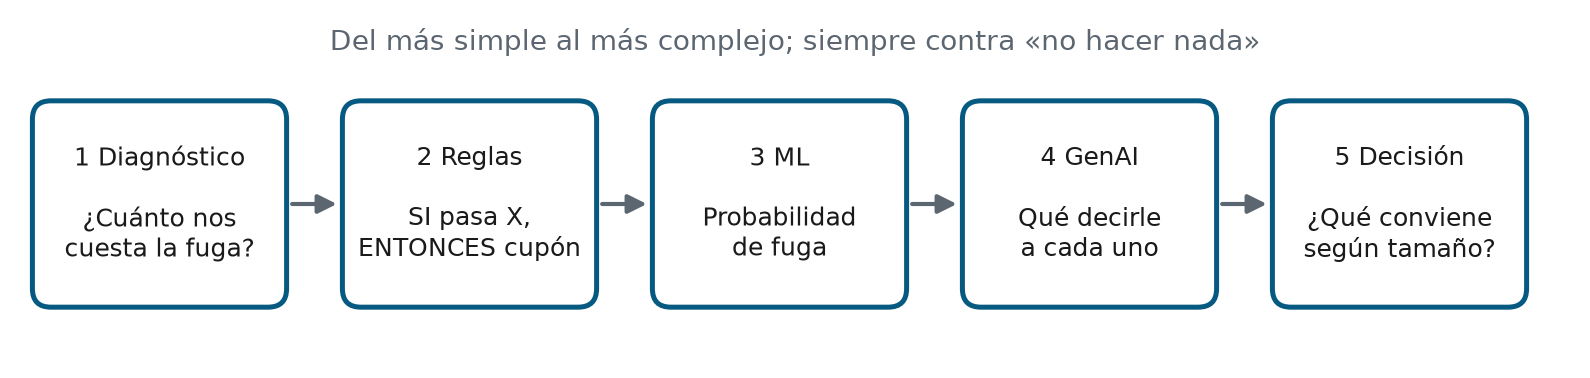

In [4]:
# Configuración
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42

# Supuestos de negocio (CLP). Si cambian, cambia la decisión: eso es parte de la lección.
LTV = 400_000          # valor de vida del cliente: lo que perdemos si se va
CAC = 150_000          # costo de adquirir un cliente nuevo (solo referencia)
COSTO_CUPON = 60_000   # margen que cede un cupón de 15%, se use bien o mal
TASA_RETENCION = 0.6   # fracción de clientes en fuga que el cupón retiene (se mide en el PoC)


def costo_negocio(y_real, contactar, retencion=TASA_RETENCION, costo_contacto=COSTO_CUPON):
    """Costo total en CLP: contactos realizados + LTV de los clientes que igual se van."""
    y = np.asarray(y_real).astype(int)
    a = np.asarray(contactar).astype(int)
    perdidos = (y * (1 - a)).sum() + (1 - retencion) * (y * a).sum()
    return a.sum() * costo_contacto + perdidos * LTV


# Control: un cliente en fuga contactado y uno fiel contactado
assert costo_negocio([1, 0], [1, 1]) == 2 * COSTO_CUPON + 0.4 * LTV


# Formato de resultados: montos en CLP y tabla comparativa de estrategias
def fmt_clp(x: float) -> str:
    x = float(x)
    if abs(x) >= 1_000_000:
        return f"${x/1_000_000:,.1f} M"
    return f"${x:,.0f}"


def tabla(filas) -> pd.DataFrame:
    out = pd.DataFrame(filas).set_index("estrategia")
    for col in ("accuracy", "recall", "precisión"):
        out[col] = out[col].map("{:.0%}".format)
    for col in ("costo", "ahorro vs nada"):
        out[col] = out[col].map(fmt_clp)
    return out


In [5]:
# Estilo visual (solo configuración; se omite en el PDF)
from matplotlib import rcParams

COLOR = {
    "verde": "#2C5F2D",
    "azul": "#065A82",
    "rojo": "#B85042",
    "gris": "#5C6670",
    "fondo": "#FAFBFC",
    "grid": "#E6E9ED",
}

rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 220,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15,
    "figure.facecolor": "white",
    "axes.facecolor": COLOR["fondo"],
    "axes.edgecolor": "#D0D5DD",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COLOR["grid"],
    "grid.linewidth": 0.7,
    "grid.alpha": 1.0,
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.frameon": True,
    "legend.fancybox": False,
    "legend.framealpha": 0.95,
    "legend.edgecolor": "#D0D5DD",
    "lines.linewidth": 2.2,
})

FIG_W = 7.2  # ancho útil A4

pd.set_option("display.max_colwidth", 40)
pd.set_option("display.precision", 2)


def estilo_ejes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(length=0)

## Bloque 1: El problema en datos

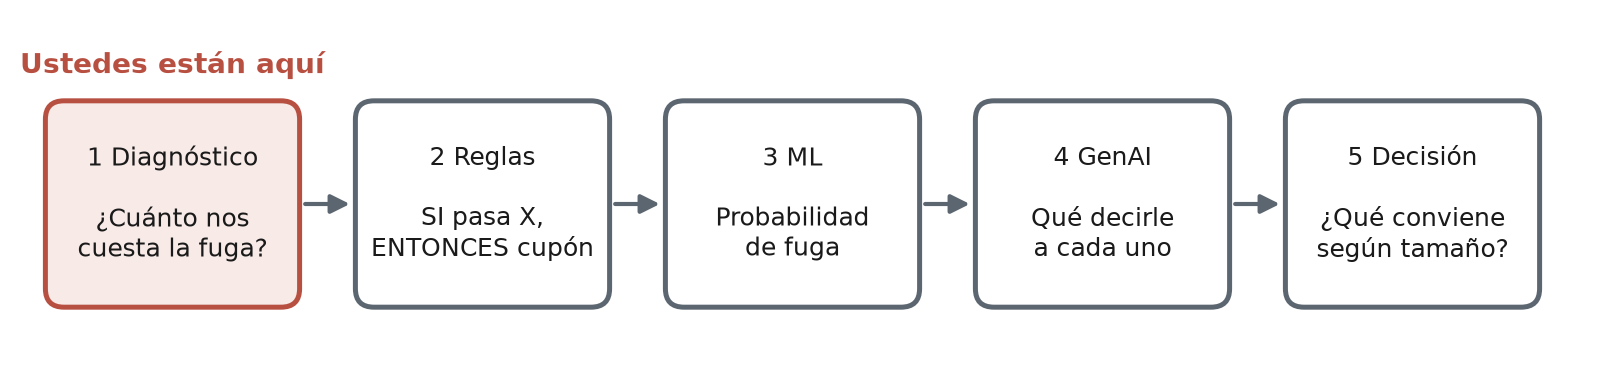

> **En 30 segundos.** Medimos cuánto nos cuesta la fuga si no hacemos nada. Traducimos cada error a pesos. Esa cifra es la vara que toda solución debe superar.

**El conflicto.** Paula tiene un presupuesto de cupones y un jefe que pide resultados. Antes de gastar un peso, necesita saber cuánto pierde hoy.

Del caso de la presentación:

| Concepto | Valor | Qué significa |
|---|---|---|
| *Churn* (fuga) | ~20% | No compran en los 90 días siguientes a la fecha de corte |
| LTV (*Lifetime Value*) | $400.000 | Lo que vale un cliente a lo largo del tiempo |
| CAC (*Customer Acquisition Cost*) | $150.000 | Lo que cuesta conseguir uno nuevo |
| Cupón 15% | $60.000 | Margen que cedemos a **cada** cliente contactado |
| Tasa de retención | 60% | De los que se iban y reciben cupón, cuántos se quedan |

**Definición de *churn* en esta clase.** Fijamos una **fecha de corte**: el día en que decidimos a quién contactar.

> ***churn* = 1** si el cliente estaba activo en la fecha de corte y **no compra en los 90 días siguientes**. Si compra en esos 90 días, ***churn* = 0**.

Las columnas del CRM (días sin comprar, tickets, NPS, etc.) se miden **hasta** la fecha de corte. La etiqueta *churn* mira **después** de la fecha de corte. Por eso el modelo predice algo que todavía no ocurre.

Ojo: la regla de 90 días del bloque 2 mira **hacia atrás** (días sin comprar a la fecha de corte). La definición de *churn* mira **hacia adelante**. Son cosas distintas, aunque usen el mismo número.

En este dataset sintético la columna `churn` ya viene calculada. Con datos reales, se construye con esta definición a partir del historial de compras.

La tasa de retención es un **supuesto**: el cupón no salva a todos. En la vida real se mide con un grupo de control durante el PoC (*Proof of Concept*, prueba de concepto).

Con esos supuestos, el costo de cualquier estrategia es:

> **Costo = cupones enviados × $60.000 + clientes que igual se van × $400.000**

Usamos un dataset **sintético** de 500 clientes (como un CRM, pero inventado para la clase): así enseñamos sin datos personales reales.

**Analogía: el balde con agujero.** Conseguir clientes es llenar un balde; la fuga es el agujero. Cada cliente que se va se lleva su LTV de $400.000, y reemplazarlo cuesta un CAC de $150.000. Tapar el agujero suele salir más barato que echar más agua.

In [6]:
df = pd.read_csv("data.csv")
print(f"Filas: {len(df):,}  |  Churn: {df['churn'].mean():.1%}")
df.sample(5, random_state=SEED)[[
    "nombre", "dias_ultima_compra", "inactividad_relativa", "nps",
    "tickets_soporte", "categoria_favorita", "ultimo_producto", "churn",
]].rename(columns={
    "nombre": "Nombre",
    "dias_ultima_compra": "Días sin compra",
    "inactividad_relativa": "Inactividad relativa",
    "nps": "NPS",
    "tickets_soporte": "Tickets",
    "categoria_favorita": "Categoría",
    "ultimo_producto": "Último producto",
    "churn": "Churn",
})

Filas: 500  |  Churn: 19.8%


,Nombre,Días sin compra,Inactividad relativa,NPS,Tickets,Categoría,Último producto,Churn
361,Catalina,4,0.07,10,2,Libros,Libro de cocina chilena,0
73,Felipe,20,2.00,0,3,Deportes,Set yoga,0
374,Antonia,6,0.11,6,2,Moda,Polerón con capucha,0
155,Constanza,1,0.02,5,1,Hogar,Aspiradora robot,1
104,Antonia,41,0.84,4,1,Libros,El problema de los tres cuerpos,0


**Dos columnas que conviene entender**

1. **NPS (*Net Promoter Score*):** nota de 0 a 10 que el cliente da a la pregunta “¿nos recomendaría?”.
2. **Inactividad relativa:** días sin comprar divididos por la antigüedad en meses. Noventa días sin comprar es alarmante para un cliente de 3 meses y normal para uno de 5 años.

### Regla de oro: el examen no se mira antes de tiempo

Separamos el 30% de los clientes como **test** (examen). Todo lo que decidamos (umbrales, reglas, modelos) se calibra con el 70% restante, **train** (entrenamiento). Al final medimos en test. Si calibramos mirando el examen, el resultado se ve mejor de lo que será en producción.

**Analogía:** train es la guía de ejercicios con la que estudiamos; test es la prueba. Si alguien conoce la prueba antes de rendirla, saca un 7, pero no aprendió nada.

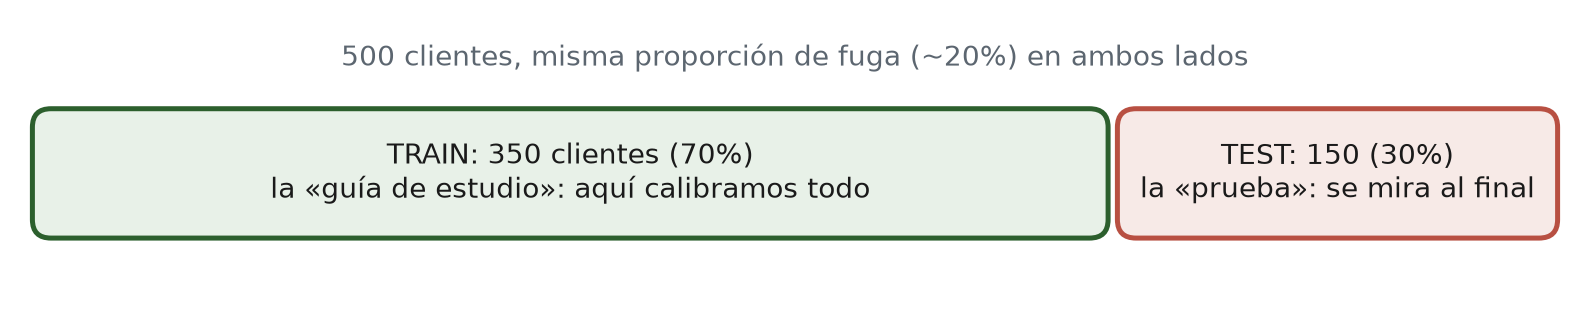

In [7]:
train, test = train_test_split(df, test_size=0.3, random_state=SEED, stratify=df["churn"])
print(f"Train: {len(train)} clientes  |  churn {train['churn'].mean():.1%}")
print(f"Test:  {len(test)} clientes  |  churn {test['churn'].mean():.1%}")

Train: 350 clientes  |  churn 19.7%
Test:  150 clientes  |  churn 20.0%


### Exploración rápida (solo en train)

**Predigan:** ¿qué señal separa mejor a quienes se van: días sin comprar, NPS, tickets de soporte o inactividad relativa?

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


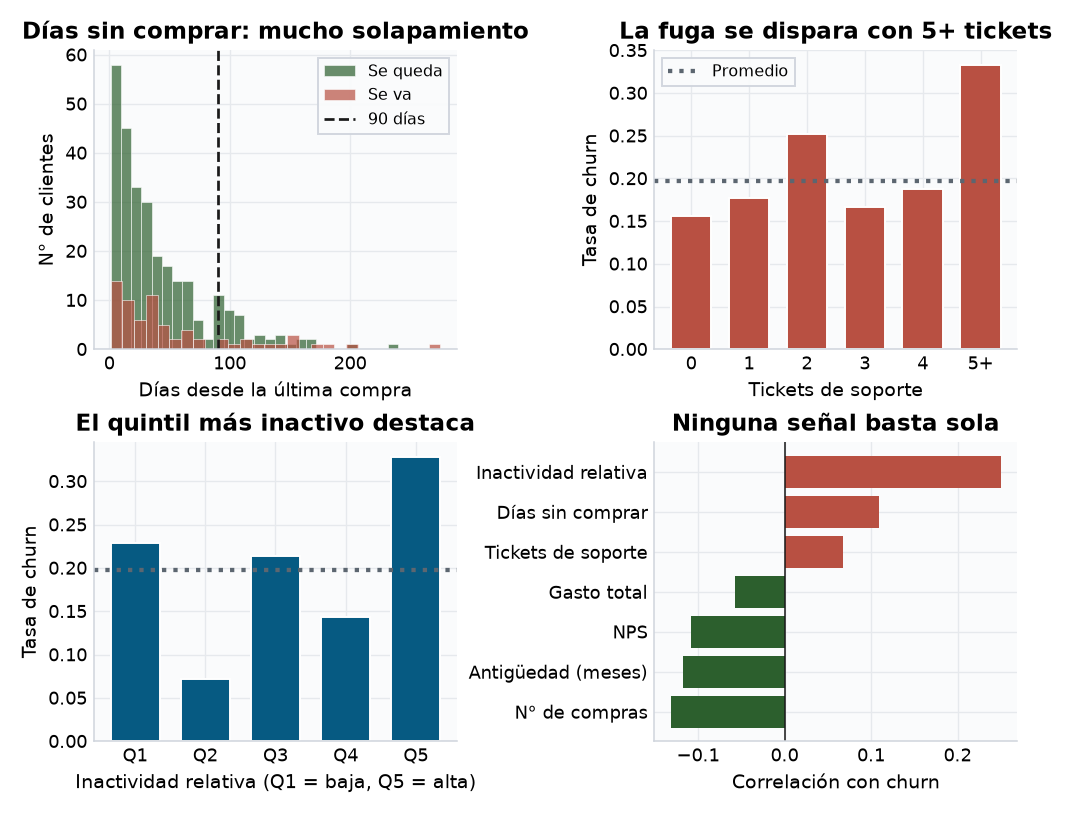

In [8]:
ETIQUETAS = {
    "antiguedad_meses": "Antigüedad (meses)",
    "gasto_total": "Gasto total",
    "num_compras": "N° de compras",
    "dias_ultima_compra": "Días sin comprar",
    "inactividad_relativa": "Inactividad relativa",
    "tickets_soporte": "Tickets de soporte",
    "nps": "NPS",
}

fig, axes = plt.subplots(2, 2, figsize=(FIG_W, 5.6), constrained_layout=True)

ax = axes[0, 0]
for valor, nombre, color in ((0, "Se queda", COLOR["verde"]), (1, "Se va", COLOR["rojo"])):
    ax.hist(train.loc[train["churn"] == valor, "dias_ultima_compra"], bins=28, alpha=0.7,
            label=nombre, color=color, edgecolor="white", linewidth=0.4)
ax.axvline(90, color="#1A1A1A", linestyle="--", linewidth=1.4, label="90 días")
ax.set(xlabel="Días desde la última compra", ylabel="N° de clientes",
       title="Días sin comprar: mucho solapamiento")
ax.legend(fontsize=8)

ax = axes[0, 1]
tk = train.groupby(train["tickets_soporte"].clip(upper=5))["churn"].mean()
ax.bar([str(i) if i < 5 else "5+" for i in tk.index], tk.values, color=COLOR["rojo"],
       edgecolor="white", width=0.7)
ax.axhline(train["churn"].mean(), color=COLOR["gris"], linestyle=":", label="Promedio")
ax.set(xlabel="Tickets de soporte", ylabel="Tasa de churn", title="La fuga se dispara con 5+ tickets")
ax.legend(fontsize=8)

ax = axes[1, 0]
quintil = pd.qcut(train["inactividad_relativa"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
ir = train.groupby(quintil, observed=True)["churn"].mean()
ax.bar(ir.index.astype(str), ir.values, color=COLOR["azul"], edgecolor="white", width=0.7)
ax.axhline(train["churn"].mean(), color=COLOR["gris"], linestyle=":")
ax.set(xlabel="Inactividad relativa (Q1 = baja, Q5 = alta)", ylabel="Tasa de churn",
       title="El quintil más inactivo destaca")

ax = axes[1, 1]
corr = train[list(ETIQUETAS)].corrwith(train["churn"]).rename(ETIQUETAS).sort_values()
ax.barh(corr.index, corr.values,
        color=[COLOR["rojo"] if v > 0 else COLOR["verde"] for v in corr.values])
ax.axvline(0, color="#1A1A1A", linewidth=0.8)
ax.set(xlabel="Correlación con churn", title="Ninguna señal basta sola")

for ax in axes.flat:
    estilo_ejes(ax)
plt.show()

**Qué se ve en los gráficos**

1. **Días sin comprar:** las dos distribuciones se superponen casi por completo. Cortar en 90 días contacta a muchos que no se iban y deja pasar a muchos que sí.
2. **Inactividad relativa** es la señal más fuerte. **Tickets** tiene correlación baja, pero la fuga sube en el extremo (5 o más): la señal está en la cola. El EDA (*Exploratory Data Analysis*, análisis exploratorio) ya sugiere qué señales usar.
3. **Todas las correlaciones son débiles.** Ninguna variable predice sola: anticipa que ningún método será perfecto.

In [9]:
# Costo del problema en toda la cartera
n_churn = int(df["churn"].sum())
pd.DataFrame([
    {"concepto": "Clientes en cartera", "valor": f"{len(df):,}"},
    {"concepto": "Clientes que se van", "valor": f"{n_churn:,} ({n_churn / len(df):.0%})"},
    {"concepto": "LTV perdido (costo de no hacer nada)", "valor": fmt_clp(costo_negocio(df["churn"], 0 * df["churn"]))},
    {"concepto": "Referencia: reponerlos vía CAC", "valor": fmt_clp(n_churn * CAC)},
]).set_index("concepto")

,valor
concepto,
Clientes en cartera,500
Clientes que se van,99 (20%)
LTV perdido (costo de no hacer nada),$39.6 M
Referencia: reponerlos vía CAC,$14.8 M


El LTV ya mide la pérdida; el CAC solo dimensiona cuánto costaría reponer esos clientes. No los sumamos para no contar dos veces.

### La vara mínima: dos estrategias sin inteligencia

Toda solución debe ganarle a estas dos:

1. **No hacer nada:** no gastamos en cupones y perdemos a todos los que se van.
2. **Cupón a todos:** gastamos en todos y retenemos al 60% de los que se iban.

**Predigan:** ¿cuál de las dos cuesta menos? ¿Qué *accuracy* (porcentaje de aciertos) tiene “no hacer nada”?

In [10]:
def evaluar(nombre, y_real, contactar, **supuestos):
    y = np.asarray(y_real).astype(int)
    a = np.asarray(contactar).astype(int)
    tp = int((y * a).sum())
    costo = costo_negocio(y, a, **supuestos)
    return {
        "estrategia": nombre,
        "contactados": int(a.sum()),
        "TP": tp,
        "FP": int(((1 - y) * a).sum()),
        "FN": int((y * (1 - a)).sum()),
        "accuracy": (y == a).mean(),
        "recall": tp / y.sum(),
        "precisión": tp / a.sum() if a.sum() else 0.0,
        "costo": costo,
        "ahorro vs nada": costo_negocio(y, 0 * y) - costo,
    }


y_test = test["churn"].to_numpy()
COSTO_NADA = costo_negocio(y_test, 0 * y_test)
base = [
    evaluar("No hacer nada", y_test, 0 * y_test),
    evaluar("Cupón a todos", y_test, 1 + 0 * y_test),
]
tabla(base)

,contactados,TP,FP,FN,accuracy,recall,precisión,costo,ahorro vs nada
estrategia,,,,,,,,,
No hacer nada,0,0,0,30,80%,0%,0%,$12.0 M,$0
Cupón a todos,150,30,120,0,20%,100%,20%,$13.8 M,$-1.8 M


**Lectura**

1. **La paradoja del *accuracy*:** “no hacer nada” acierta en el 80% de los casos (nadie se va... y casi siempre es cierto). Aun así es la estrategia que deja ir a todos. Por eso hoy no elegimos por *accuracy*, sino por costo.
2. **Cupón a todos sale más caro que no hacer nada:** regalamos margen a 4 de cada 5 clientes que no se iban. Intervenir a ciegas destruye valor.

**Glosario** (lo usamos en todas las tablas):

| Sigla | Nombre | En este caso |
|---|---|---|
| TP | Verdadero positivo | Se iba, lo contactamos |
| FP | Falso positivo | No se iba, le regalamos un cupón |
| FN | Falso negativo | Se iba y no lo vimos venir |
| *Recall* | Sensibilidad | De los que se iban, qué fracción contactamos |
| Precisión | Precisión | De los contactados, qué fracción se iba |

Cada combinación de lo que hicimos y lo que pasó tiene un precio. Esta es la “boleta” de cada acierto y error:

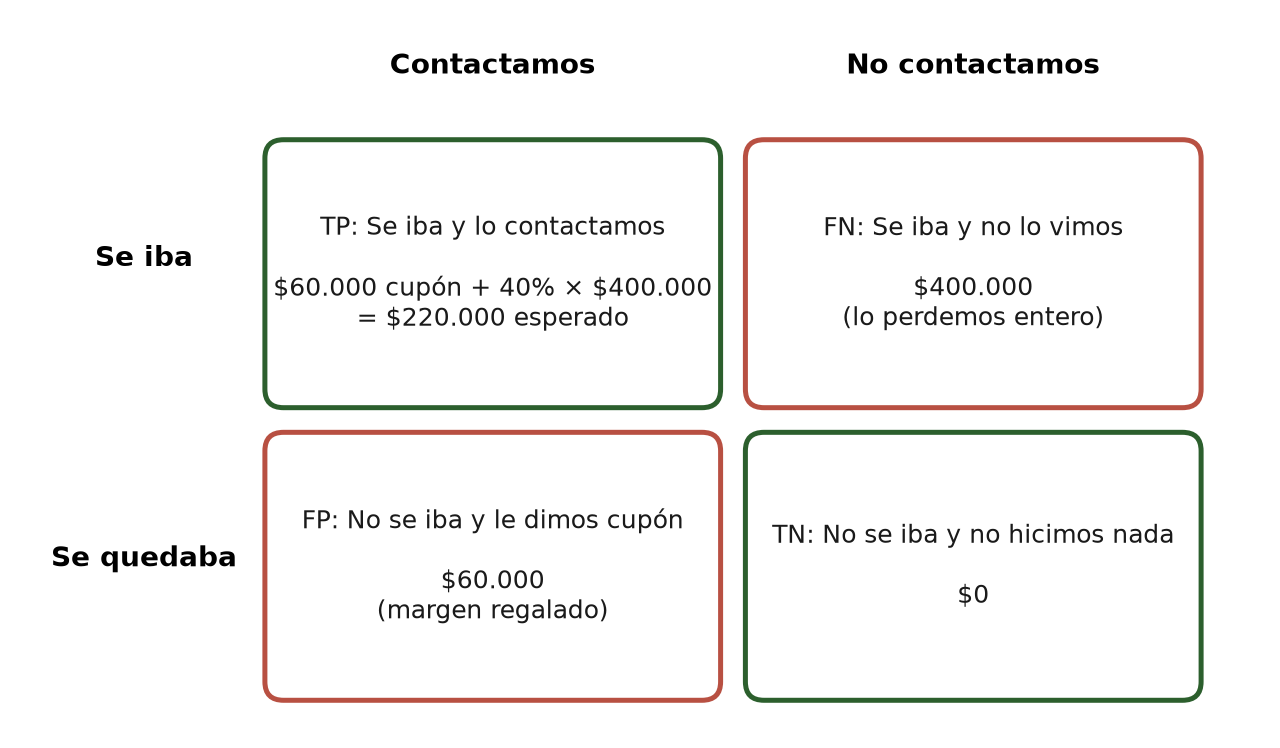

Fíjense en la asimetría: no ver a un cliente que se va (FN) cuesta 6,7 veces más que regalarle un cupón a uno que no se iba (FP).

**Discusión:** antes de elegir solución, ¿qué KPI (*Key Performance Indicator*, indicador clave) movemos: tasa de churn, LTV recuperado o costo total? (slide 7)

**Autoevaluación del bloque 1**

**Pregunta 1.** Un modelo acierta en el 80% de los clientes. ¿Basta eso para usarlo?

<details><summary>Ver respuesta</summary>

No. “No hacer nada” también acierta en el 80%, porque solo el 20% se va. Hay que mirar cuánto cuestan los errores, no cuántos aciertos hay.

</details>

**Pregunta 2.** ¿Qué error es más caro en este caso: FP o FN?

<details><summary>Ver respuesta</summary>

FN: perdemos al cliente, $400.000. Un FP cuesta $60.000 de margen regalado.

</details>

### Conozcan a Javier

Javier es uno de los 150 clientes de test. Su ficha es lo que el CRM ve hoy. La columna *churn* queda oculta: es lo que queremos adivinar.

**Predigan:** ¿Javier se va o se queda? Anoten su apuesta.

In [11]:
# Javier: el cliente que seguimos en toda la clase (está en test: los modelos no lo ven al entrenar)
JAVIER = "C0321"
javier = test.set_index("customer_id").loc[JAVIER]
javier.drop("churn").to_frame("Javier")

,Javier
nombre,Javier
antiguedad_meses,9
gasto_total,133956.0
num_compras,6
dias_ultima_compra,79
inactividad_relativa,8.78
tickets_soporte,2
nps,6
categoria_favorita,Moda
ultimo_producto,Polerón con capucha


**Punto de control.** Deberían ver la tabla de costos con “No hacer nada” y “Cupón a todos”, y la ficha de Javier. Si algo falla, usen el menú *Kernel*, opción *Restart & Run All*.

**Próximo bloque.** El área comercial propone una regla simple. ¿Vería a Javier?

## Bloque 2: Solución 1, reglas

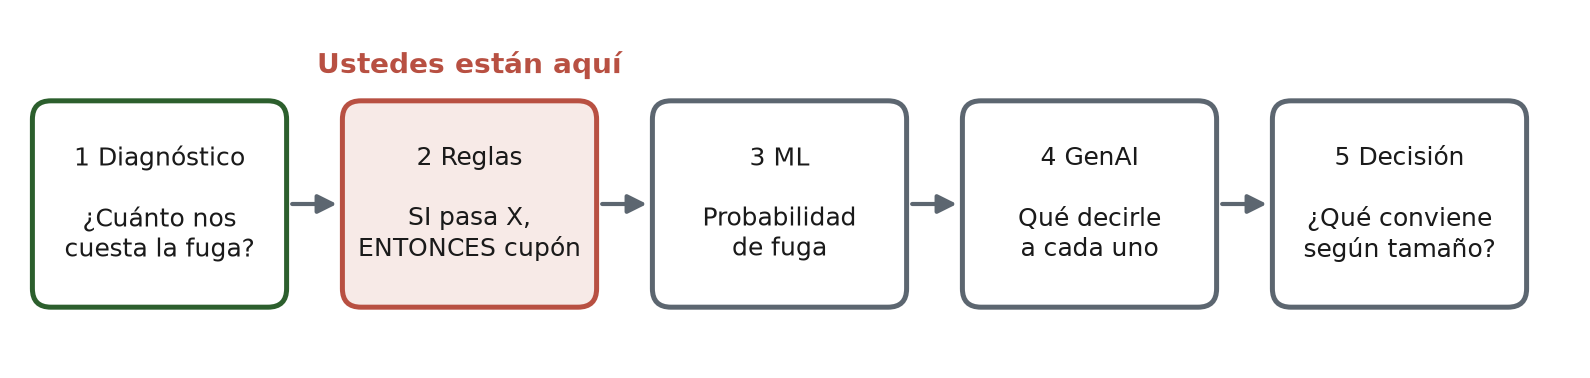

> **En 30 segundos.** Probamos la regla intuitiva de 90 días y dos reglas calibradas con datos. La intuición falla; el dato ayuda.

**El conflicto.** El área comercial ya tiene una respuesta: “a los que llevan 90 días sin comprar, cupón”. Es rápida y barata. Paula debe decidir si confía en ella.

Implementamos la regla de la presentación:

> **SI** el cliente lleva más de 90 días sin comprar **ENTONCES** enviarle un cupón de 15%

**Analogía: la alarma de humo.** Una regla es como una alarma con sensibilidad fija. Si es muy sensible, suena cada vez que cocinamos (FP). Si es poco sensible, no suena con un incendio real (FN). No piensa: solo compara un número con un límite.

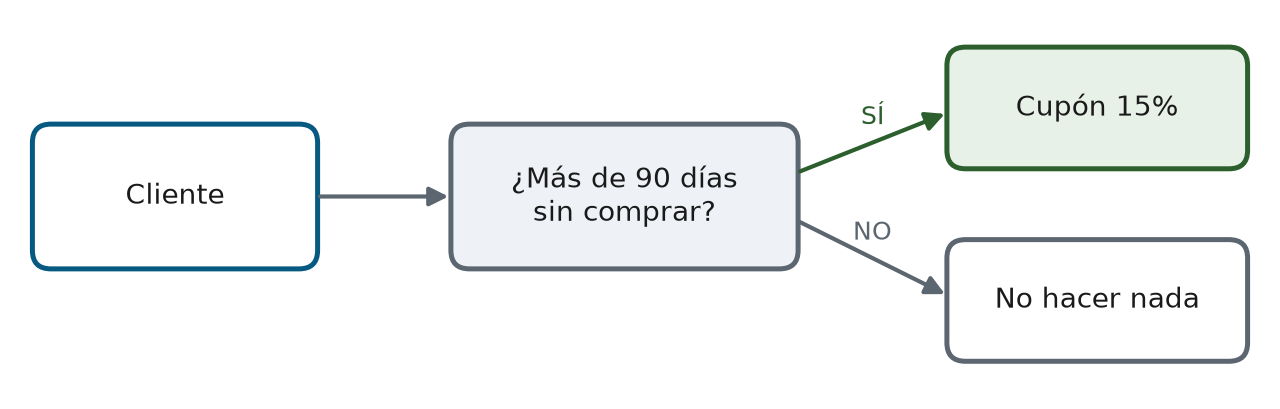

**Predigan:** ¿la regla de 90 días le gana a “no hacer nada”?

In [12]:
regla_90 = evaluar("Regla: >90 días", y_test, test["dias_ultima_compra"] > 90)
tabla(base + [regla_90])

,contactados,TP,FP,FN,accuracy,recall,precisión,costo,ahorro vs nada
estrategia,,,,,,,,,
No hacer nada,0,0,0,30,80%,0%,0%,$12.0 M,$0
Cupón a todos,150,30,120,0,20%,100%,20%,$13.8 M,$-1.8 M
Regla: >90 días,17,4,13,26,74%,13%,24%,$12.1 M,"$-60,000"


**Lectura en negocio**

La regla de 90 días **cuesta un poco más que no hacer nada**: contacta a muchos clientes fieles (FP) y deja pasar a casi todos los que se van (FN). El número 90 salió de la intuición, no del dato.

Dos mejoras sin ML, ambas calibradas **solo en train**:

1. **Mejor número:** buscar el umbral de días que minimiza el costo.
2. **Mejores señales:** usar lo que mostró el EDA, inactividad relativa y tickets de soporte.

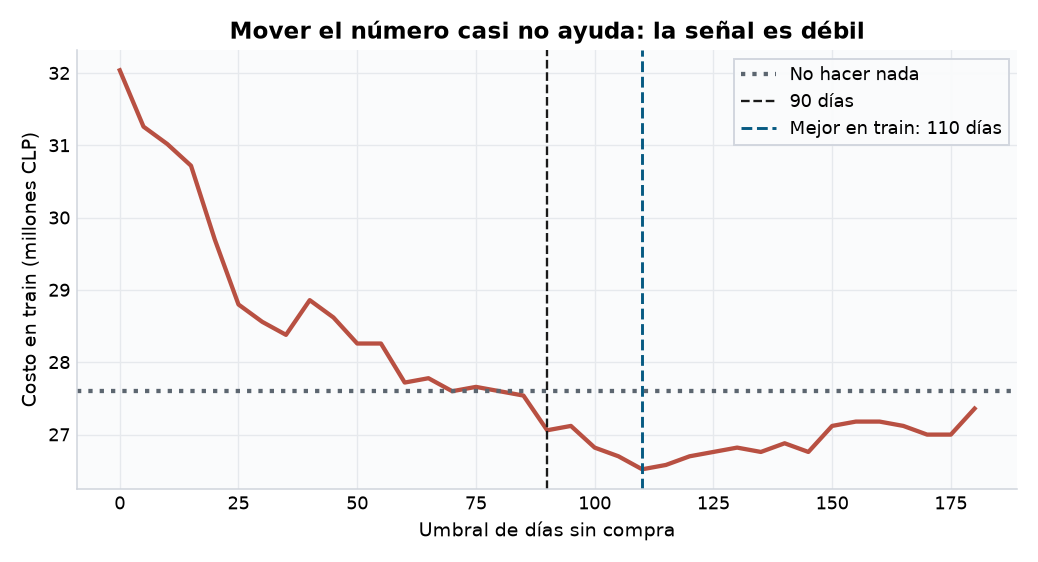

,contactados,TP,FP,FN,accuracy,recall,precisión,costo,ahorro vs nada
estrategia,,,,,,,,,
No hacer nada,0,0,0,30,80%,0%,0%,$12.0 M,$0
Cupón a todos,150,30,120,0,20%,100%,20%,$13.8 M,$-1.8 M
Regla: >90 días,17,4,13,26,74%,13%,24%,$12.1 M,"$-60,000"
Regla: >110 días,10,3,7,27,77%,10%,30%,$11.9 M,"$120,000"
Regla: inactividad >3 o tickets ≥5,34,13,21,17,75%,43%,38%,$10.9 M,$1.1 M


In [13]:
# Mejora 1: el umbral de días que minimiza el costo en train
umbrales = np.arange(0, 181, 5)
costos_train = [costo_negocio(train["churn"], train["dias_ultima_compra"] > u) for u in umbrales]
u_opt = int(umbrales[np.argmin(costos_train)])

fig, ax = plt.subplots(figsize=(FIG_W, 3.8), constrained_layout=True)
ax.plot(umbrales, np.array(costos_train) / 1e6, color=COLOR["rojo"])
ax.axhline(costo_negocio(train["churn"], 0 * train["churn"]) / 1e6, color=COLOR["gris"],
           linestyle=":", label="No hacer nada")
ax.axvline(90, color="#1A1A1A", linestyle="--", linewidth=1.2, label="90 días")
ax.axvline(u_opt, color=COLOR["azul"], linestyle="--", linewidth=1.5, label=f"Mejor en train: {u_opt} días")
ax.set(xlabel="Umbral de días sin compra", ylabel="Costo en train (millones CLP)",
       title="Mover el número casi no ayuda: la señal es débil")
ax.legend()
estilo_ejes(ax)
plt.show()

# Mejora 2: dos señales del EDA, combinadas con "o"
grilla = [(i, k) for i in np.arange(1, 6.01, 0.25) for k in range(1, 8)]
i_opt, k_opt = min(grilla, key=lambda g: costo_negocio(
    train["churn"], (train["inactividad_relativa"] > g[0]) | (train["tickets_soporte"] >= g[1])))
regla_eda = (test["inactividad_relativa"] > i_opt) | (test["tickets_soporte"] >= k_opt)

reglas = [
    regla_90,
    evaluar(f"Regla: >{u_opt} días", y_test, test["dias_ultima_compra"] > u_opt),
    evaluar(f"Regla: inactividad >{i_opt:g} o tickets ≥{k_opt}", y_test, regla_eda),
]
tabla(base + reglas)

**¿Y Javier?** Revisemos qué decide cada regla con su ficha. Después revelamos si se fue.

In [14]:
# Qué decide cada regla con la ficha de Javier
dias = javier["dias_ultima_compra"]
ve_eda = javier["inactividad_relativa"] > i_opt or javier["tickets_soporte"] >= k_opt
print(f"Días sin comprar: {dias}  →  regla de 90 días: {'cupón' if dias > 90 else 'no hacer nada'}")
print(f"Inactividad relativa: {javier['inactividad_relativa']:.1f} (límite {i_opt:g}); "
      f"tickets: {javier['tickets_soporte']} (límite {k_opt})  →  regla del EDA: "
      f"{'cupón' if ve_eda else 'no hacer nada'}")
print(f"\nLa verdad: Javier {'se fue' if javier['churn'] else 'se quedó'}.")
if javier["churn"] and dias <= 90:
    print(f"Para la regla de 90 días, Javier es un FN: perdemos {fmt_clp(LTV)}.")

Días sin comprar: 79  →  regla de 90 días: no hacer nada
Inactividad relativa: 8.8 (límite 3); tickets: 2 (límite 5)  →  regla del EDA: cupón

La verdad: Javier se fue.
Para la regla de 90 días, Javier es un FN: perdemos $400,000.


**Lo que Paula aprendió (bloque 2)**

Ajustar el número de días casi no cambia nada: el problema era la señal, no el número. La regla que usa **las señales que mostró el EDA** sí le gana a no hacer nada, contactando a pocos clientes.

Una buena regla no sale de la intuición: sale de mirar el dato. Y sigue siendo explicable en una frase. Javier lo muestra con nombre: la regla de 90 días no lo ve; la regla del EDA sí, porque mira su inactividad relativa y no los días a secas. ¿Puede un modelo hacerlo mejor combinando **todas** las señales?

**Autoevaluación del bloque 2**

**Pregunta.** ¿Por qué elegimos el número de días mirando solo train y no test?

<details><summary>Ver respuesta</summary>

Porque test es la prueba. Si elegimos el número mirando test, el resultado se ve mejor de lo que será con clientes nuevos.

</details>

**Punto de control.** Deberían ver el gráfico de umbrales, la tabla con tres reglas y lo que cada regla decide con Javier. Si algo falla, usen el menú *Kernel*, opción *Restart & Run All*.

**Próximo bloque.** Las reglas miran una o dos señales. ¿Qué pasa si un modelo mira todas?

## Bloque 3: Solución 2, *Machine Learning*

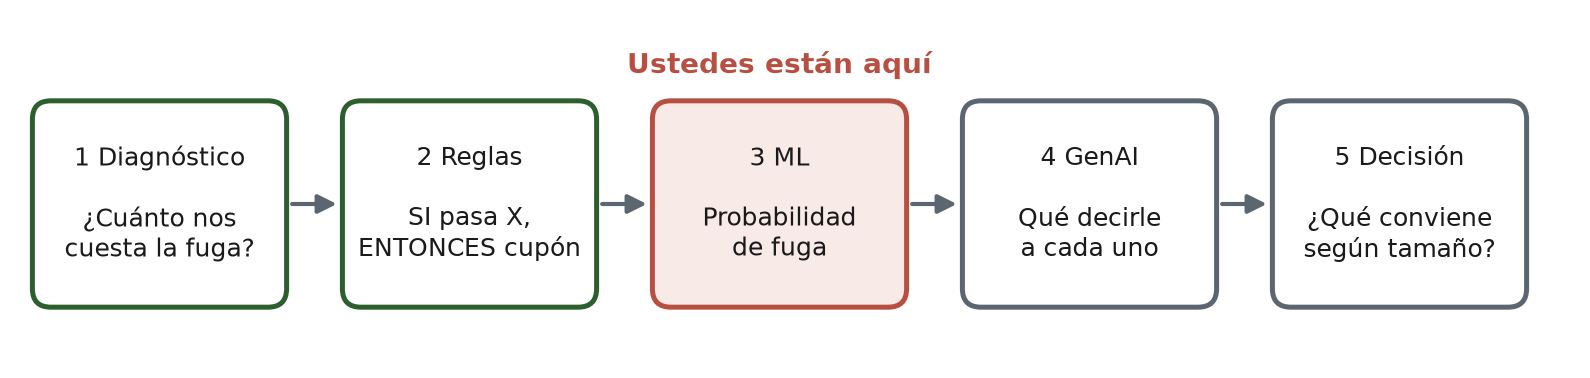

> **En 30 segundos.** Un modelo combina todas las señales y entrega una probabilidad de fuga. El umbral para contactar sale del negocio, no del modelo.

**El conflicto.** La regla basada en datos funciona, pero mira solo dos señales. El equipo de datos promete algo mejor. Paula se pregunta si vale la pena.

En vez de escribir nosotros la regla, mostramos al algoritmo ejemplos de clientes que se fueron y que se quedaron. El algoritmo aprende cómo combinar las señales y entrega una **probabilidad de fuga** por cliente.

| | Reglas | *Machine Learning* |
|---|---|---|
| Quién decide la lógica | Una persona | El algoritmo, con nuestros datos |
| Cuántas señales usa | Una o dos | Todas a la vez |
| Qué entrega | Sí o no | Una probabilidad entre 0 y 1 |

**Analogía: el médico que aprende de fichas.** Un médico joven revisa miles de fichas de pacientes que se enfermaron y que no. Con el tiempo, aprende qué combinación de síntomas anticipa la enfermedad. El modelo hace lo mismo con fichas de clientes: no recibe reglas, recibe ejemplos.

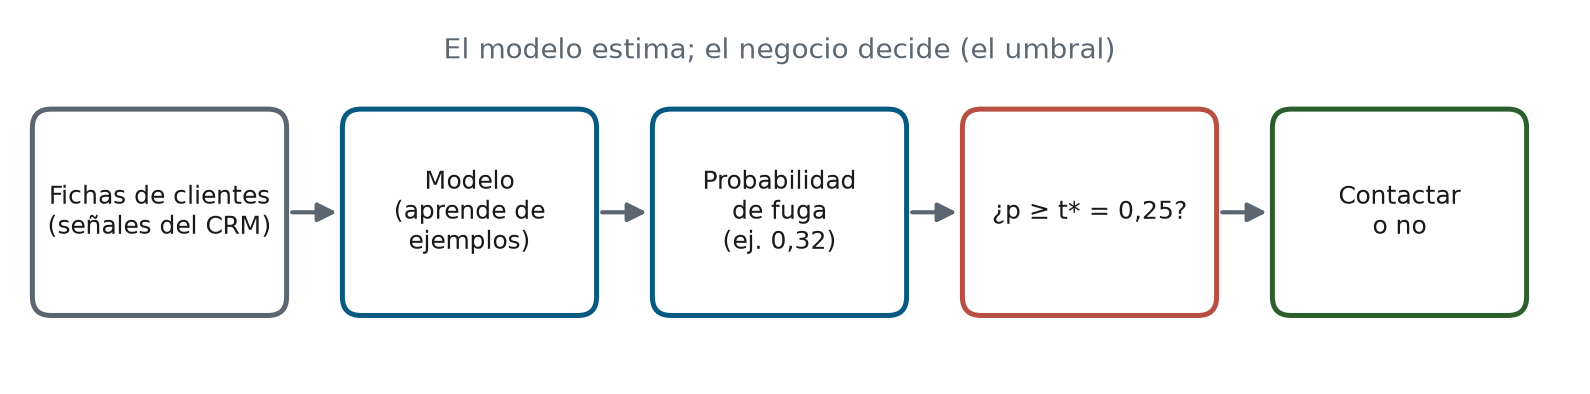

Probamos dos modelos: **regresión logística** (simple, una suma ponderada de señales) y **Random Forest** (más complejo, cientos de árboles de decisión).

### ¿Desde qué probabilidad conviene contactar?

Contactar a un cliente con probabilidad de fuga *p* conviene si lo que esperamos salvar supera lo que cuesta el cupón:

> *p* × 60% × $400.000 > $60.000  →  contactar si *p* > **t\* = cupón / (retención × LTV)**

El umbral sale del negocio, no del modelo. El umbral “de fábrica” de 0,5 supone que equivocarse hacia un lado cuesta lo mismo que hacia el otro.

**Analogía: la regla del paraguas.** ¿Lleva paraguas si el pronóstico dice 30% de lluvia? Depende de cuánto le molesta cargarlo y de cuánto le molesta mojarse. Con el cupón pasa igual: el umbral depende de lo que cuesta el cupón y de lo que vale el cliente.

**Paso a paso, con un cliente de p = 0,30:**

1. Si se iba y le damos el cupón, lo retenemos con 60% de probabilidad. Valor esperado salvado: 0,30 × 0,60 × $400.000 = **$72.000**.
2. El cupón cuesta **$60.000**.
3. $72.000 > $60.000: conviene contactarlo.
4. El punto de equilibrio está donde ambos lados son iguales: *p* × 0,60 × $400.000 = $60.000. Despejando, *p* = $60.000 / $240.000 = **0,25**.

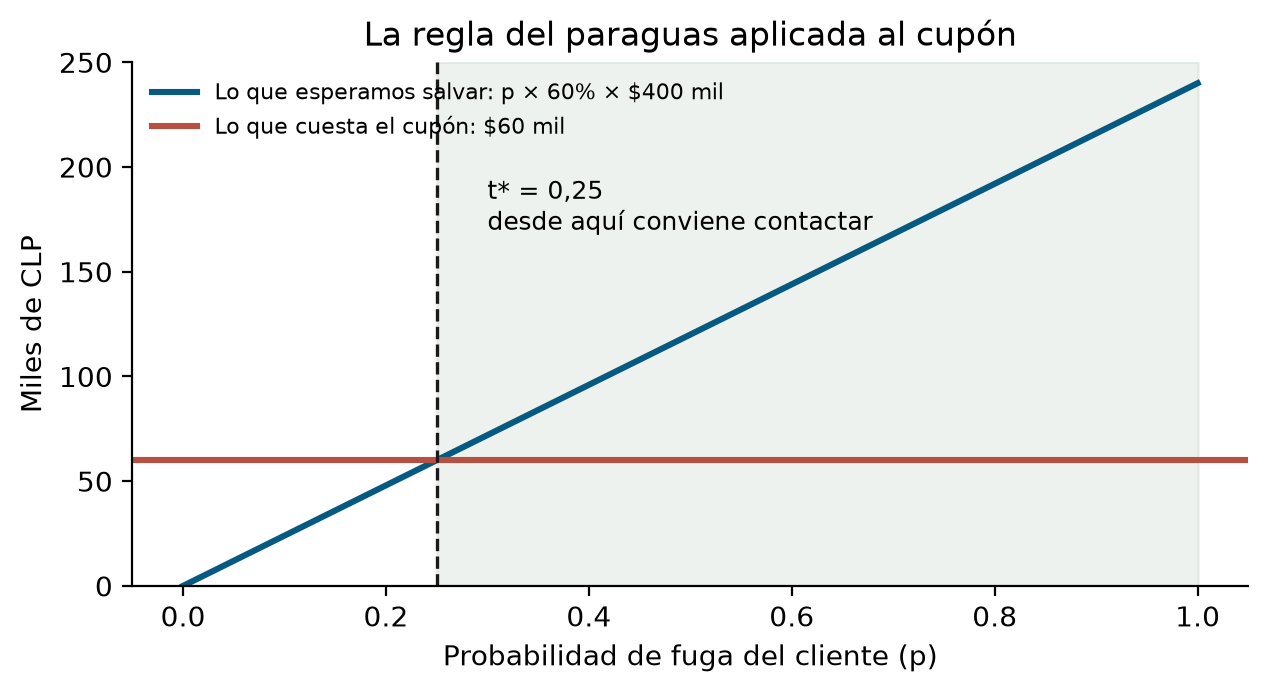

In [15]:
def features(d):
    X = d.drop(columns=["customer_id", "nombre", "ultimo_producto", "churn"])
    return pd.get_dummies(X, columns=["categoria_favorita"], drop_first=True, dtype=int)


X = features(df)
X_train, X_test = X.loc[train.index], X.loc[test.index]
y_train = train["churn"].to_numpy()

modelos = {
    "Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=5,
                                            random_state=SEED),
}

# Validación cruzada en train: el modelo predice a cada cliente sin haberlo visto
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof, proba = {}, {}
for nombre, m in modelos.items():
    oof[nombre] = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    proba[nombre] = m.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    print(f"{nombre:14s} AUC validación cruzada {roc_auc_score(y_train, oof[nombre]):.2f}"
          f"  |  AUC test {roc_auc_score(y_test, proba[nombre]):.2f}")

Logística      AUC validación cruzada 0.62  |  AUC test 0.71
Random Forest  AUC validación cruzada 0.57  |  AUC test 0.67


**Cómo leer el AUC** (*Area Under the Curve*, área bajo la curva ROC): mide qué tan bien el modelo ordena a los clientes por riesgo. 0,5 es azar; 1,0 es perfecto. Valores entre 0,55 y 0,7 indican señal **débil pero real**, coherente con las correlaciones del EDA.

<details><summary><b>Para profundizar:</b> ¿cómo se calibra sin tocar test?</summary>

La **validación cruzada** (5 *folds*) divide train en cinco partes: el modelo predice cada parte entrenando con las otras cuatro. Así obtenemos predicciones *out-of-fold* (OOF, fuera de la muestra de entrenamiento) para calibrar sin tocar test.

**Analogía:** son cinco controles de práctica. En cada uno, una parte de la guía queda escondida y sirve de control; con el resto se estudia. Al final, cada ejercicio fue control una vez.

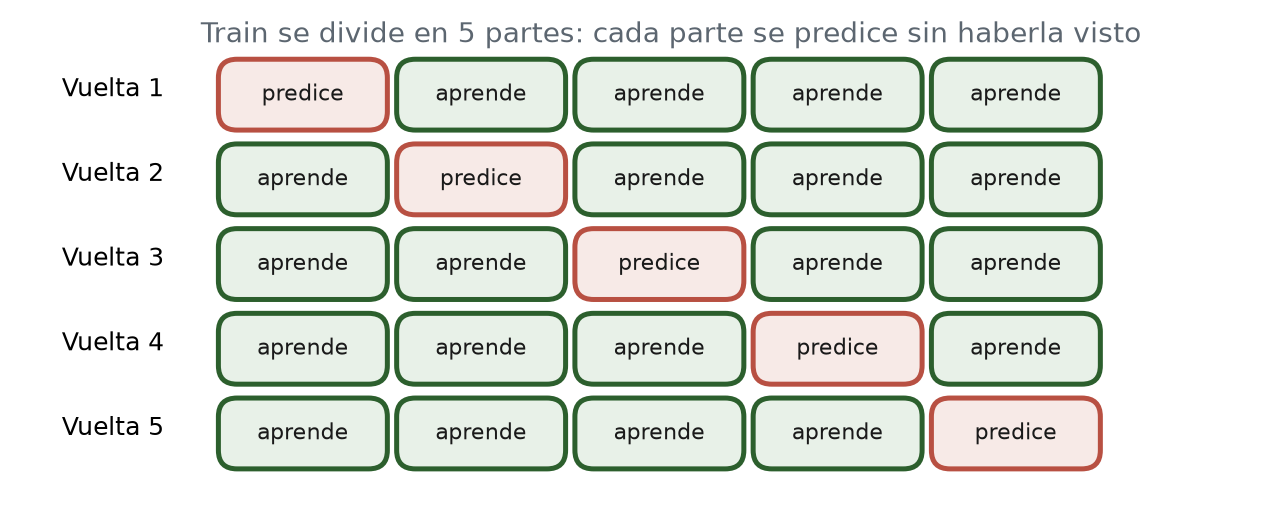

</details>

### Verificamos t\* con datos de train

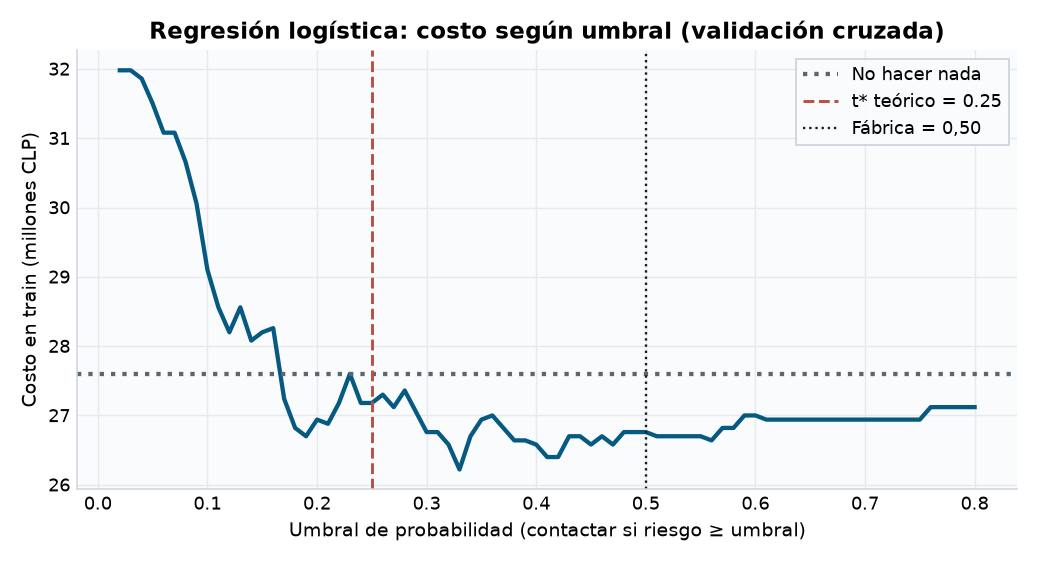

t* teórico: 0.25  |  mínimo empírico en train: 0.33


In [16]:
T_STAR = COSTO_CUPON / (TASA_RETENCION * LTV)

umbrales_p = np.arange(0.02, 0.81, 0.01)
costo_oof = np.array([costo_negocio(y_train, oof["Logística"] >= t) for t in umbrales_p])
t_oof = umbrales_p[np.argmin(costo_oof)]

fig, ax = plt.subplots(figsize=(FIG_W, 3.8), constrained_layout=True)
ax.plot(umbrales_p, costo_oof / 1e6, color=COLOR["azul"])
ax.axhline(costo_negocio(y_train, 0 * y_train) / 1e6, color=COLOR["gris"], linestyle=":",
           label="No hacer nada")
ax.axvline(T_STAR, color=COLOR["rojo"], linestyle="--", linewidth=1.5, label=f"t* teórico = {T_STAR:.2f}")
ax.axvline(0.5, color="#1A1A1A", linestyle=":", linewidth=1.2, label="Fábrica = 0,50")
ax.set(xlabel="Umbral de probabilidad (contactar si riesgo ≥ umbral)",
       ylabel="Costo en train (millones CLP)",
       title="Regresión logística: costo según umbral (validación cruzada)")
ax.legend()
estilo_ejes(ax)
plt.show()
print(f"t* teórico: {T_STAR:.2f}  |  mínimo empírico en train: {t_oof:.2f}")

El mínimo empírico no coincide exactamente con t\*: con 350 clientes la curva tiene ruido. Usamos **t\*** porque sale del negocio y no depende del ruido de una muestra. Lo importante: ambos quedan muy por debajo de 0,5.

**Predigan:** con el umbral de fábrica (0,5), ¿el modelo le gana a la mejor regla? ¿Y el Random Forest, que es más sofisticado?

In [17]:
modelos_eval = [
    evaluar("Logística, umbral 0,50", y_test, proba["Logística"] >= 0.5),
    evaluar(f"Logística, umbral t* = {T_STAR:.2f}", y_test, proba["Logística"] >= T_STAR),
    evaluar(f"Random Forest, umbral t* = {T_STAR:.2f}", y_test, proba["Random Forest"] >= T_STAR),
]
tabla(base + reglas[-1:] + modelos_eval)

,contactados,TP,FP,FN,accuracy,recall,precisión,costo,ahorro vs nada
estrategia,,,,,,,,,
No hacer nada,0,0,0,30,80%,0%,0%,$12.0 M,$0
Cupón a todos,150,30,120,0,20%,100%,20%,$13.8 M,$-1.8 M
Regla: inactividad >3 o tickets ≥5,34,13,21,17,75%,43%,38%,$10.9 M,$1.1 M
"Logística, umbral 0,50",3,3,0,27,82%,10%,100%,$11.5 M,"$540,000"
"Logística, umbral t* = 0.25",35,16,19,14,78%,53%,46%,$10.3 M,$1.7 M
"Random Forest, umbral t* = 0.25",21,10,11,20,79%,33%,48%,$10.9 M,$1.1 M


**¿Y Javier?** El modelo le asigna una probabilidad de fuga. Comparemos esa probabilidad con los dos umbrales.

In [18]:
p_javier = pd.Series(proba["Logística"], index=test["customer_id"])[JAVIER]
print(f"Probabilidad de fuga de Javier: {p_javier:.2f}")
for nombre_u, u in [("umbral de fábrica 0,50", 0.5), (f"t* = {T_STAR:.2f}", T_STAR)]:
    print(f"  Con {nombre_u}: {'contactar' if p_javier >= u else 'no contactar'}")

Probabilidad de fuga de Javier: 0.31
  Con umbral de fábrica 0,50: no contactar
  Con t* = 0.25: contactar


**Lo que Paula aprendió (bloque 3)**

1. **El umbral es una decisión económica.** Con 0,5 el modelo contacta a casi nadie y ahorra poco. Con t\* le gana a todo lo anterior.
2. **Más complejo no es mejor.** El Random Forest es más sofisticado y aquí rinde peor: con 350 clientes de entrenamiento y señales débiles, la complejidad no tiene de dónde aprender.
3. **La mejor regla queda cerca del modelo.** El ML gana, pero por poco. Esa diferencia tendrá que pagar el costo de construir y mantener el modelo (bloque 5).
4. **El umbral tiene nombre y apellido.** Con 0,5 el modelo deja ir a Javier; con t\* lo contacta.

**Advertencia de tamaño:** test tiene 150 clientes. Un solo cliente en fuga vale $400.000, así que diferencias pequeñas entre filas pueden ser ruido.

### ¿En qué se fija el modelo?

La regresión logística es transparente: cada variable tiene un **coeficiente**. Como estandarizamos las variables, los coeficientes son comparables. Positivo sube el riesgo; negativo lo baja.

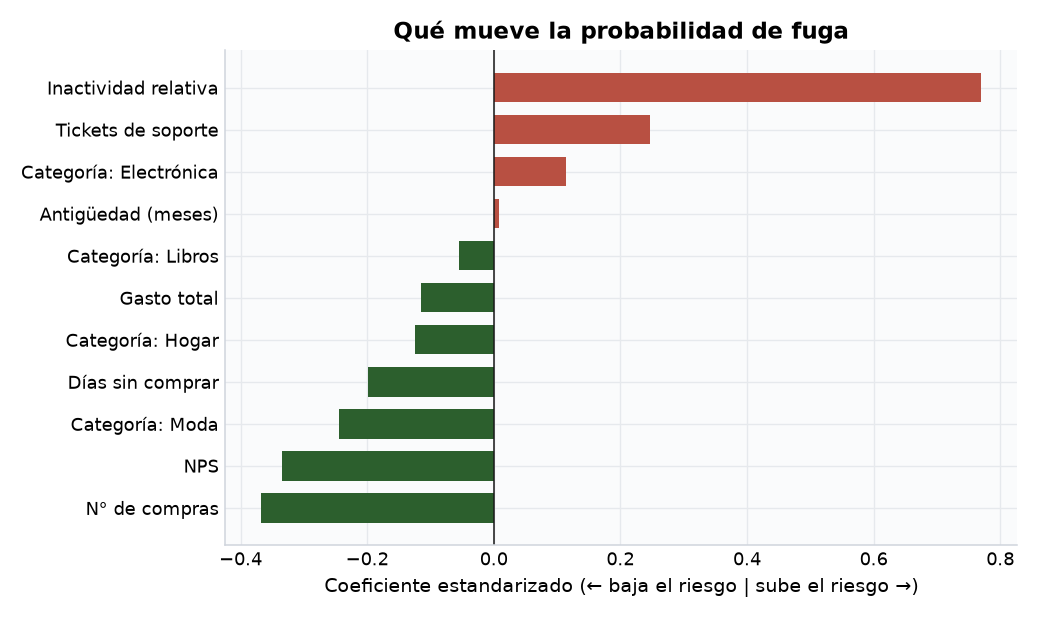

In [19]:
lr = modelos["Logística"][-1]
nombres = [ETIQUETAS.get(c, "Categoría: " + c.split("_")[-1]) for c in X.columns]
coef = pd.Series(lr.coef_[0], index=nombres).sort_values()

fig, ax = plt.subplots(figsize=(FIG_W, 4.2), constrained_layout=True)
ax.barh(coef.index, coef.values,
        color=[COLOR["rojo"] if v > 0 else COLOR["verde"] for v in coef.values], height=0.7)
ax.axvline(0, color="#1A1A1A", linewidth=0.8)
ax.set(xlabel="Coeficiente estandarizado (← baja el riesgo | sube el riesgo →)",
       title="Qué mueve la probabilidad de fuga")
estilo_ejes(ax)
plt.show()

**Lectura para no expertos**

Las barras más largas son las señales que más pesan. Comparen con el EDA: el modelo confirma lo que vimos (tickets e inactividad suben el riesgo; más compras y mejor NPS lo bajan) y además combina todo en un solo puntaje.

<details><summary><b>Para profundizar:</b> ¿por qué “Días sin comprar” aparece negativo?</summary>

**Ojo con “Días sin comprar”:** aparece negativo. No significa que comprar menos proteja. La inactividad relativa ya contiene los días (días ÷ antigüedad), y cuando dos variables miden casi lo mismo, el modelo reparte el efecto entre ellas. Los coeficientes de variables relacionadas no se leen por separado.

</details>

Para un comité esto importa: un modelo explicable se aprueba y se audita más fácil.

**Discusión (5 min):** en su problema, ¿qué es más caro: actuar de más (FP) o dejar escapar un caso (FN)? ¿Cuál sería su t\*?

**Autoevaluación del bloque 3**

**Pregunta 1.** El modelo le asigna a un cliente una probabilidad de fuga de 0,20. ¿Lo contactamos?

<details><summary>Ver respuesta</summary>

No. 0,20 está bajo t\* = 0,25. El valor esperado salvado (0,20 × 0,60 × $400.000 = $48.000) es menor que el cupón ($60.000).

</details>

**Pregunta 2.** Si el cupón costara más, ¿el umbral sube o baja?

<details><summary>Ver respuesta</summary>

Sube. Un contacto más caro exige estar más seguro de que el cliente se va.

</details>

**Punto de control.** Deberían ver dos líneas de AUC, la curva de t\*, la tabla de modelos, la probabilidad de Javier y el gráfico de coeficientes. Si algo falla, usen el menú *Kernel*, opción *Restart & Run All*.

**Próximo bloque.** El modelo dice a quién contactar. ¿Qué le decimos a Javier?

## Bloque 4: Solución 3, GenAI encima del ML

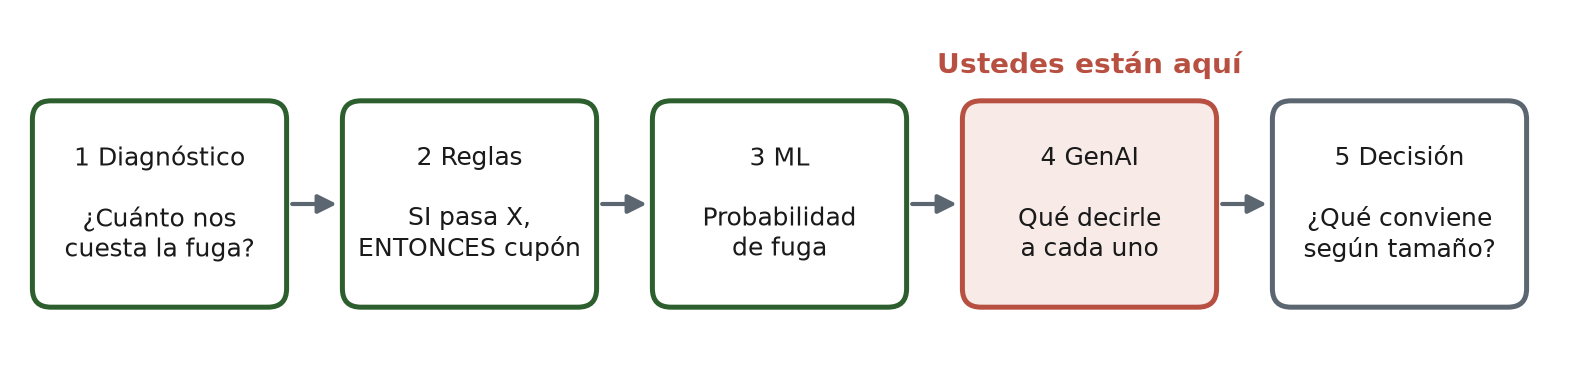

> **En 30 segundos.** El ML elige a quién contactar; GenAI redacta qué decirle. Los *tokens* cuestan casi nada. Lo caro es el equipo y la revisión humana.

**El conflicto.** Paula ya sabe a quién contactar. Ahora marketing pregunta: “¿Les mandamos a todos el mismo correo?”.

Frase clave de la presentación:

> **El modelo dice a quién contactar; GenAI ayuda a decidir qué decirle.**

**Analogía:** el ML es el jefe de ventas que elige a quién llamar; GenAI es el redactor que escribe la carta para cada uno. Un gran redactor no sirve de nada si las cartas llegan a las personas equivocadas.

Comparamos tres niveles de mensaje, del más barato al más rico:

1. **Plantilla fija:** mismo texto para todos ($0).
2. **“LLM simulado”:** plantillas con variación (sin API, *Application Programming Interface*; sirve para la clase).
3. **LLM real** (*Large Language Model*, modelo de lenguaje): Claude de Anthropic. Requiere `ANTHROPIC_API_KEY` en un archivo `.env` en esta carpeta o en una superior (y `ANTHROPIC_WORKSPACE_ID` si la llave no está asociada a un *workspace*). Sin clave, la celda usa la versión simulada.

**Supuesto clave:** un mensaje personalizado retiene más que la plantilla. Suponemos 70% en vez de 60%. Este número **no se sabe de antemano**: se mide con una prueba A/B en el PoC.

In [21]:
RETENCION_GENAI = 0.70   # supuesto: se valida con prueba A/B
USD_CLP = 950            # supuesto de tipo de cambio
MODELO_LLM = "claude-sonnet-5-5"
PRECIO_USD_MTOK = {"entrada": 2.0, "salida": 10.0}   # USD por millón de tokens (precio de lista)

cand = test[["customer_id", "nombre", "categoria_favorita", "ultimo_producto"]].assign(
    prob_churn=proba["Logística"])
contactar_ml = cand["prob_churn"] >= T_STAR
print(f"Clientes que el modelo manda a contactar: {contactar_ml.sum()} de {len(cand)}")
top = cand[contactar_ml].sort_values("prob_churn", ascending=False).head(3)
top.round(2)

Clientes que el modelo manda a contactar: 35 de 150


,customer_id,nombre,categoria_favorita,ultimo_producto,prob_churn
249,C0249,Camila,Hogar,Aspiradora robot,0.88
271,C0271,Sebastián,Libros,Libro de cocina chilena,0.76
170,C0170,Antonia,Libros,Libro de cocina chilena,0.53


In [22]:
# Versión 1: plantilla fija
def email_plantilla(cliente):
    return (
        f"Hola {cliente['nombre']},\n\n"
        f"Te extrañamos. Aquí tienes un 15% de descuento.\n\n"
        f"Saludos."
    )


print("VERSIÓN 1: Plantilla fija\n" + "=" * 50)
for _, c in top.iterrows():
    print(email_plantilla(c))
    print("-" * 50)

VERSIÓN 1: Plantilla fija
Hola Camila,

Te extrañamos. Aquí tienes un 15% de descuento.

Saludos.
--------------------------------------------------
Hola Sebastián,

Te extrañamos. Aquí tienes un 15% de descuento.

Saludos.
--------------------------------------------------
Hola Antonia,

Te extrañamos. Aquí tienes un 15% de descuento.

Saludos.
--------------------------------------------------


In [23]:
# Versión 2: LLM simulado (plantillas contextuales, sin API)
import random

random.seed(123)

APERTURAS = [
    "Hace tiempo que no te vemos por acá",
    "Notamos que hace un rato no nos visitas",
    "Pensamos en ti hace poco",
]
PUENTES = {
    "Libros": [
        "después de leer {producto}, tenemos más títulos de {categoria} que podrían interesarte",
        "si disfrutaste {producto}, hay otras novedades en {categoria} que acabamos de recibir",
    ],
    "Moda": [
        "vimos que te llevaste {producto}; tenemos nuevas piezas de {categoria} esta temporada",
        "ese {producto} fue una buena elección; te dejamos una selección de {categoria}",
    ],
    "Electrónica": [
        "{producto} fue una buena elección; hay lanzamientos en {categoria} que podrían complementarlo",
        "después de {producto}, te seleccionamos artículos de {categoria} con buenas reseñas",
    ],
    "Hogar": [
        "tu compra de {producto} nos hizo pensar en novedades de {categoria}",
        "complementa {producto} con algo de nuestra nueva colección de {categoria}",
    ],
    "Deportes": [
        "esperamos que {producto} te esté sirviendo; tenemos accesorios de {categoria} que podrían sumarte",
        "tras {producto}, te dejamos lo más nuevo en {categoria}",
    ],
}
CIERRES = [
    "Como gesto, te dejamos un 15% de descuento esta semana.",
    "Activamos un 15% de descuento, válido por siete días.",
]


def email_llm_simulado(cliente):
    puente = random.choice(PUENTES[cliente["categoria_favorita"]]).format(
        producto=cliente["ultimo_producto"], categoria=cliente["categoria_favorita"])
    return (
        f"Hola {cliente['nombre']},\n\n"
        f"{random.choice(APERTURAS)}; {puente}. {random.choice(CIERRES)}\n\n"
        f"Saludos cordiales,\nEquipo de Atención"
    )


print("VERSIÓN 2: LLM simulado\n" + "=" * 50)
for _, c in top.iterrows():
    print(email_llm_simulado(c))
    print("-" * 50)

VERSIÓN 2: LLM simulado
Hola Camila,

Notamos que hace un rato no nos visitas; tu compra de Aspiradora robot nos hizo pensar en novedades de Hogar. Como gesto, te dejamos un 15% de descuento esta semana.

Saludos cordiales,
Equipo de Atención
--------------------------------------------------
Hola Sebastián,

Notamos que hace un rato no nos visitas; si disfrutaste Libro de cocina chilena, hay otras novedades en Libros que acabamos de recibir. Como gesto, te dejamos un 15% de descuento esta semana.

Saludos cordiales,
Equipo de Atención
--------------------------------------------------
Hola Antonia,

Notamos que hace un rato no nos visitas; después de leer Libro de cocina chilena, tenemos más títulos de Libros que podrían interesarte. Activamos un 15% de descuento, válido por siete días.

Saludos cordiales,
Equipo de Atención
--------------------------------------------------


### Versión 3: LLM real

> **Sin clave no hay error.** Si no configuraron `ANTHROPIC_API_KEY`, la celda muestra la versión simulada. Es el comportamiento esperado: el resto del notebook funciona igual.

**Privacidad (Ley 21.719 de protección de datos personales):** enviamos al proveedor **solo** lo necesario para redactar: nombre de pila, categoría favorita y último producto. No enviamos RUT, gasto, NPS ni la probabilidad de fuga. Con clientes reales, además, se requiere base de licitud, contrato de encargo de tratamiento con el proveedor y revisión humana antes del envío.

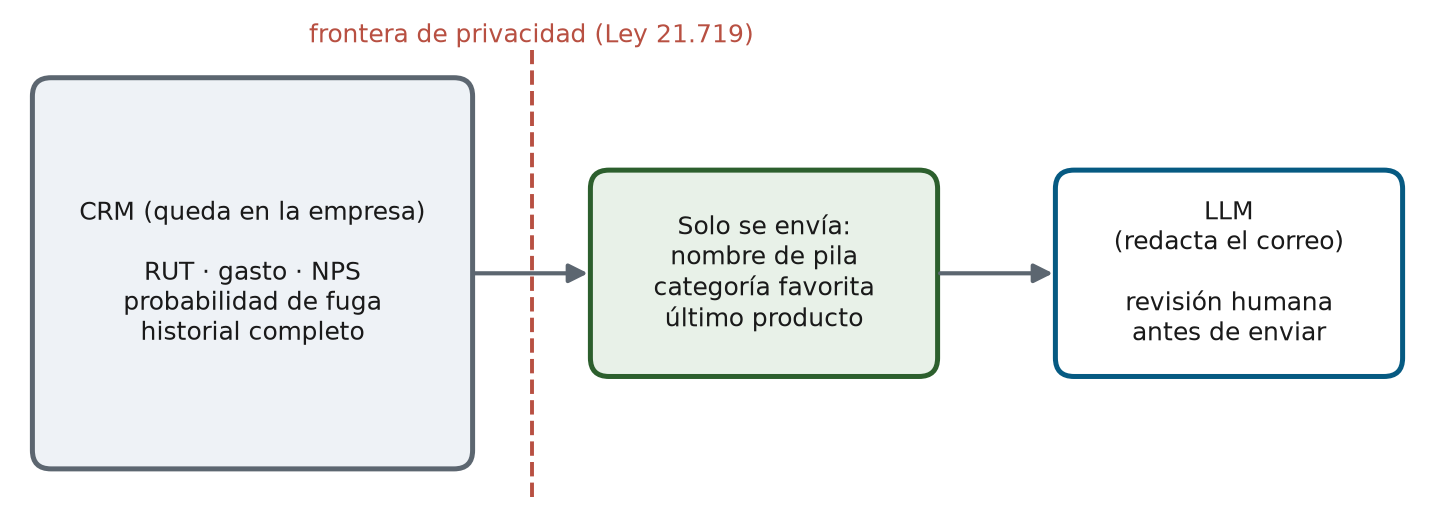

**Determinismo:** el LLM solo redacta. Los cálculos (a quién contactar, cuánto cuesta) los hace el código.

In [24]:
import os

try:
    from dotenv import load_dotenv

    load_dotenv()  # lee ANTHROPIC_API_KEY desde .env sin mostrarla
except ImportError:  # sin python-dotenv (p. ej., Colab): usa variables de entorno
    pass

SISTEMA = (
    "Eres redactor de una tienda en línea chilena. Escribes correos de reactivación "
    "breves, cálidos y profesionales, en español de Chile. Entregas solo el cuerpo del "
    "correo en texto plano: sin markdown, sin emojis y sin línea de asunto."
)


def pedir_correo(c):
    return (
        f"Redacta un correo de máximo 100 palabras para {c['nombre'].split()[0]}. "
        f"Su categoría favorita es {c['categoria_favorita']} y su última compra fue "
        f"{c['ultimo_producto']}. Ofrece un 15% de descuento válido por siete días. "
        f"Firma como Equipo de Atención."
    )


uso_tokens = []
if not os.getenv("ANTHROPIC_API_KEY"):
    print("Modo simulado (sin ANTHROPIC_API_KEY). Es normal: los correos de abajo salen de plantillas "
          "y el resto del notebook funciona igual.\n")
    for _, c in top.iterrows():
        print(email_llm_simulado(c) + "\n" + "-" * 50)
else:
    import anthropic

    ws = os.getenv("ANTHROPIC_WORKSPACE_ID")
    client = anthropic.Anthropic(default_headers={"anthropic-workspace-id": ws} if ws else None)
    print(f"VERSIÓN 3: LLM real ({MODELO_LLM})\n" + "=" * 50)
    for _, c in top.iterrows():
        try:
            r = client.messages.create(
                model=MODELO_LLM,
                max_tokens=400,
                thinking={"type": "between_tools"},  # sin razonamiento previo: es solo redacción
                output_config={"effort": "low"},
                system=SISTEMA,
                messages=[{"role": "user", "content": pedir_correo(c)}],
            )
        except anthropic.APIError as e:
            print(f"Falló la API ({type(e).__name__}: {getattr(e, 'message', e)}).\nSe usa la versión simulada.\n")
            print(email_llm_simulado(c) + "\n" + "-" * 50)
            continue
        uso_tokens.append((r.usage.input_tokens, r.usage.output_tokens))
        print("".join(b.text for b in r.content if b.type == "text"))
        print("-" * 50)

VERSIÓN 3: LLM real (claude-sonnet-5-5)
Hola, Camila:

Esperamos que tu aspiradora robot esté haciendo bien su trabajo y que tu casa se mantenga impecable sin mucho esfuerzo.

Hace un tiempo que no te vemos por aquí y queremos agradecerte por preferirnos. Como sabemos que lo tuyo es el hogar, te regalamos un 15% de descuento en toda la categoría Hogar, válido por siete días desde hoy.

Es una buena ocasión para renovar espacios, sumar accesorios o dar ese toque que le falta a tu casa.

Te esperamos en nuestra tienda.

Un abrazo,
Equipo de Atención
--------------------------------------------------
Hola, Sebastián:

Hace un tiempo que no sabemos de ti y queremos que vuelvas a pasar por nuestra tienda. Sabemos que los libros son lo tuyo, y esperamos que tu Libro de cocina chilena te haya dado varias tardes ricas en la cocina.

Para celebrar tu regreso, tenemos un 15% de descuento en toda la categoría Libros, válido por siete días desde hoy. Es una buena excusa para sumar nuevas lecturas 

**¿Y Javier?** Esto es exactamente lo que sale de la empresa hacia el proveedor del LLM, y el correo que recibiría Javier (versión simulada, sin costo de API).

In [25]:
print("Lo que se envía al LLM:\n" + pedir_correo(javier) + "\n")
print("Correo para Javier (simulado):\n" + email_llm_simulado(javier))

Lo que se envía al LLM:
Redacta un correo de máximo 100 palabras para Javier. Su categoría favorita es Moda y su última compra fue Polerón con capucha. Ofrece un 15% de descuento válido por siete días. Firma como Equipo de Atención.

Correo para Javier (simulado):
Hola Javier,

Hace tiempo que no te vemos por acá; ese Polerón con capucha fue una buena elección; te dejamos una selección de Moda. Como gesto, te dejamos un 15% de descuento esta semana.

Saludos cordiales,
Equipo de Atención


**Comparen las tres versiones:** ¿cuál abrirían ustedes? ¿Cuál podría ofender o sonar falsa? ¿Quién revisa los correos antes de enviarlos?

### ¿Cuánto cuesta y cuánto rinde?

Con GenAI, cada contacto cuesta el cupón **más** los *tokens* (fragmentos de texto que cobra el proveedor). Como el mensaje retiene más, el umbral óptimo baja: conviene contactar a más clientes.

In [26]:
# Tokens por correo: medidos si hubo llamada real, estimados si no
tok_in, tok_out = np.mean(uso_tokens, axis=0) if uso_tokens else (100, 250)
costo_llm = (tok_in * PRECIO_USD_MTOK["entrada"] + tok_out * PRECIO_USD_MTOK["salida"]) / 1e6 * USD_CLP
costo_contacto_genai = COSTO_CUPON + costo_llm
T_GENAI = costo_contacto_genai / (RETENCION_GENAI * LTV)

genai = evaluar(f"Logística + GenAI, umbral {T_GENAI:.2f}", y_test, proba["Logística"] >= T_GENAI,
                retencion=RETENCION_GENAI, costo_contacto=costo_contacto_genai)
print(f"Costo LLM por correo: {fmt_clp(costo_llm)} ({'medido' if uso_tokens else 'estimado'}: "
      f"{tok_in:.0f} tokens de entrada, {tok_out:.0f} de salida)")
print(f"Costo por contacto con GenAI: {fmt_clp(costo_contacto_genai)}  |  nuevo umbral: {T_GENAI:.2f}\n")
tabla(base + reglas[-1:] + modelos_eval[1:2] + [genai])

Costo LLM por correo: $3 (medido: 185 tokens de entrada, 237 de salida)
Costo por contacto con GenAI: $60,003  |  nuevo umbral: 0.21



,contactados,TP,FP,FN,accuracy,recall,precisión,costo,ahorro vs nada
estrategia,,,,,,,,,
No hacer nada,0,0,0,30,80%,0%,0%,$12.0 M,$0
Cupón a todos,150,30,120,0,20%,100%,20%,$13.8 M,$-1.8 M
Regla: inactividad >3 o tickets ≥5,34,13,21,17,75%,43%,38%,$10.9 M,$1.1 M
"Logística, umbral t* = 0.25",35,16,19,14,78%,53%,46%,$10.3 M,$1.7 M
"Logística + GenAI, umbral 0.21",52,19,33,11,71%,63%,37%,$9.8 M,$2.2 M


**Lo que Paula aprendió (bloque 4)**

El costo de los *tokens* por correo es despreciable frente al cupón. Lo caro de GenAI **no es la API**: es el equipo que diseña los *prompts*, la revisión humana de los mensajes, el monitoreo de calidad y el cumplimiento legal. Ese costo es fijo y mensual, y lo incorporamos en el bloque 5.

GenAI aporta solo si la personalización mueve un indicador medible (la retención) y hay volumen suficiente para pagar ese costo fijo. Con Javier se ve la frontera de privacidad: al proveedor solo viajan su nombre de pila, su categoría favorita y su último producto.

**Autoevaluación del bloque 4**

**Pregunta.** ¿Por qué no enviamos la probabilidad de fuga al LLM?

<details><summary>Ver respuesta</summary>

Porque no la necesita para redactar. Al proveedor se le envían solo los datos necesarios para la finalidad. Además, la decisión de a quién contactar la toma el código, no el LLM.

</details>

**Punto de control.** Deberían ver los correos de cada versión, el correo de Javier y la tabla con GenAI. En modo simulado, esto es normal. Si algo falla, usen el menú *Kernel*, opción *Restart & Run All*.

**Próximo bloque.** Ya sabemos qué hace cada solución. Falta la pregunta del gerente: ¿cuál conviene pagar?

## Bloque 5: ¿Cuándo conviene cada solución?

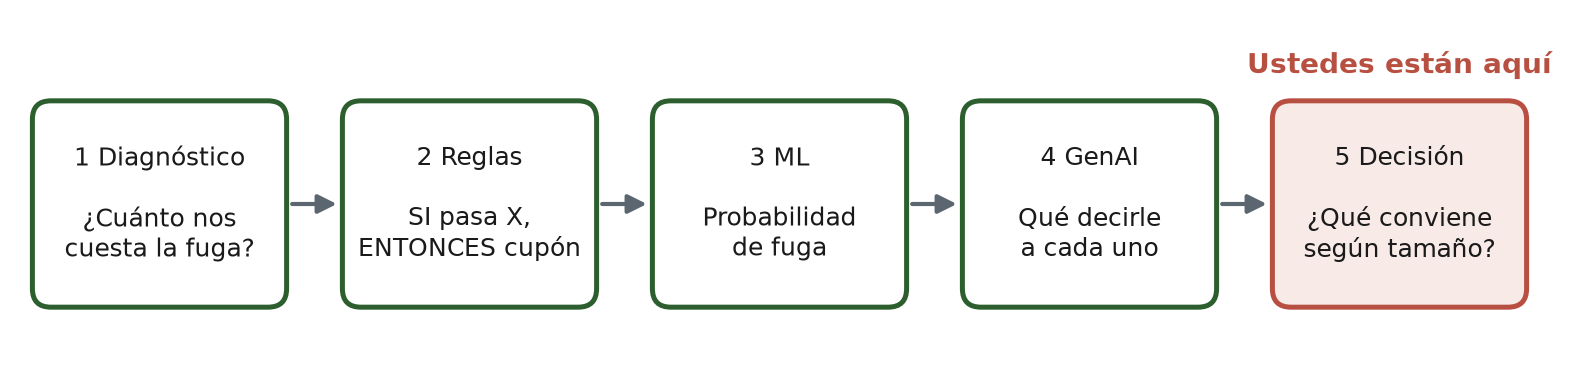

> **En 30 segundos.** Cada solución tiene un costo fijo y un ahorro por cliente. El tamaño de la base de clientes decide cuál conviene.

**El conflicto.** El gerente general no pregunta qué modelo es mejor. Pregunta cuánto cuesta y cuándo se paga.

Tesis: **no hay un ganador universal**. Depende del tamaño de la base de clientes.

Cada solución tiene dos números:

1. **Ahorro por cliente:** lo medimos en test (ahorro vs no hacer nada ÷ 150 clientes). Suponemos que el ciclo de fuga del dataset es anual.
2. **Costo fijo anual:** implementación más 12 meses de operación (supuestos de la tabla).

> **Valor neto anual = N° de clientes × ahorro por cliente − costo fijo anual**

Es el principio KISS (*Keep It Simple, Stupid*) aplicado a plata: usar la solución más simple que todavía sea rentable.

**Analogía: auto propio o Uber.** Un auto propio tiene un costo fijo alto (compra, seguro, permiso de circulación), pero cada viaje sale barato. Uber no tiene costo fijo, pero cada viaje cuesta más. Si viaja poco, conviene Uber; si viaja mucho, el auto. Con las soluciones pasa lo mismo: ML y GenAI tienen costos fijos altos y solo se pagan con muchos clientes.

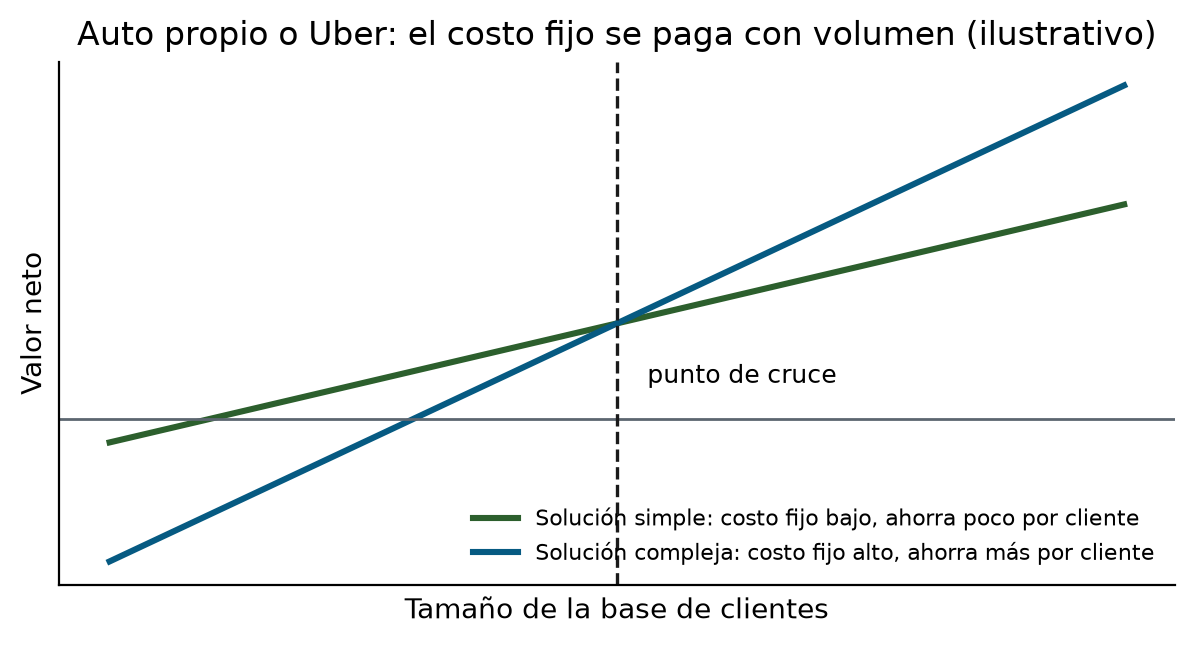

In [27]:
soluciones = pd.DataFrame([
    {"solución": "No hacer nada", "costo_impl": 0, "costo_mes": 0, "ahorro_test": 0},
    {"solución": "Reglas", "costo_impl": 2_000_000, "costo_mes": 100_000, "ahorro_test": reglas[-1]["ahorro vs nada"]},
    {"solución": "ML", "costo_impl": 15_000_000, "costo_mes": 800_000, "ahorro_test": modelos_eval[1]["ahorro vs nada"]},
    {"solución": "ML + GenAI", "costo_impl": 35_000_000, "costo_mes": 3_500_000, "ahorro_test": genai["ahorro vs nada"]},
]).set_index("solución")
soluciones["ahorro_cliente"] = soluciones["ahorro_test"] / len(test)
soluciones["costo_fijo_anual"] = soluciones["costo_impl"] + 12 * soluciones["costo_mes"]

soluciones.drop(columns="ahorro_test").map(fmt_clp).rename(columns={
    "costo_impl": "Implementación", "costo_mes": "Operación mensual",
    "ahorro_cliente": "Ahorro por cliente (medido)", "costo_fijo_anual": "Costo fijo anual",
})

,Implementación,Operación mensual,Ahorro por cliente (medido),Costo fijo anual
solución,,,,
No hacer nada,$0,$0,$0,$0
Reglas,$2.0 M,"$100,000","$7,200",$3.2 M
ML,$15.0 M,"$800,000","$11,600",$24.6 M
ML + GenAI,$35.0 M,$3.5 M,"$14,666",$77.0 M


La operación mensual de ML + GenAI incluye equipo, revisión humana de mensajes, monitoreo e infraestructura. Los *tokens* ya están dentro del ahorro por cliente.

**Predigan:** ¿desde cuántos clientes conviene el ML? ¿Y GenAI?

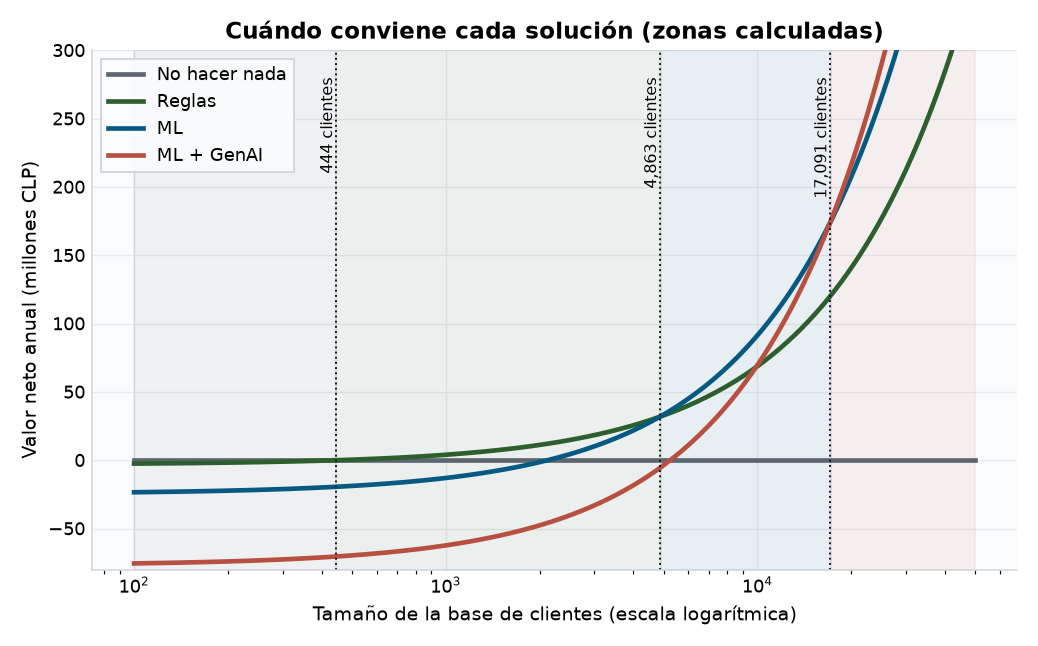

,desde,hasta,conviene
0,0,444,No hacer nada
1,444,"4,863",Reglas
2,"4,863","17,091",ML
3,"17,091",en adelante,ML + GenAI


In [28]:
ns = np.unique(np.geomspace(100, 50_000, 600).astype(int))
valor = pd.DataFrame({s: ns * f["ahorro_cliente"] - f["costo_fijo_anual"] for s, f in soluciones.iterrows()},
                     index=ns)
ganador = valor.idxmax(axis=1)
inicios = ganador[ganador.ne(ganador.shift())]

# Cruce exacto entre ganadores consecutivos: N × a1 − F1 = N × a2 − F2
filas, desde = [], 0
for previo, siguiente in zip(inicios.values, list(inicios.values[1:]) + [None]):
    if siguiente is None:
        hasta = None
    else:
        a, b = soluciones.loc[previo], soluciones.loc[siguiente]
        hasta = int((b["costo_fijo_anual"] - a["costo_fijo_anual"]) / (b["ahorro_cliente"] - a["ahorro_cliente"]))
    filas.append({"desde": f"{desde:,}", "hasta": f"{hasta:,}" if hasta else "en adelante", "conviene": previo})
    desde = hasta
cruces = pd.DataFrame(filas)

colores = {"No hacer nada": COLOR["gris"], "Reglas": COLOR["verde"], "ML": COLOR["azul"], "ML + GenAI": COLOR["rojo"]}
fig, ax = plt.subplots(figsize=(FIG_W, 4.4), constrained_layout=True)
for s in valor:
    ax.plot(ns, valor[s] / 1e6, label=s, color=colores[s], linewidth=2.4)
bordes = list(inicios.index) + [ns[-1]]
for s, x0, x1 in zip(inicios.values, bordes[:-1], bordes[1:]):
    ax.axvspan(x0, x1, color=colores[s], alpha=0.07)
for n in cruces["desde"].iloc[1:]:
    x = int(n.replace(",", ""))
    ax.axvline(x, color="#1A1A1A", linestyle=":", linewidth=1)
    ax.annotate(f"{n} clientes", (x, 280), rotation=90, ha="right", va="top", fontsize=8)
ax.set_xscale("log")
ax.set_ylim(-80, 300)
ax.set(xlabel="Tamaño de la base de clientes (escala logarítmica)", ylabel="Valor neto anual (millones CLP)",
       title="Cuándo conviene cada solución (zonas calculadas)")
ax.legend(loc="upper left")
estilo_ejes(ax)
plt.show()
cruces

**Cómo leer el gráfico**

Cada zona de color marca la solución con mayor valor neto. Las zonas y los cruces **se calculan** con los ahorros medidos y los costos fijos: si cambian los supuestos, cambian solos.

1. **Bases chicas:** no conviene invertir. Hasta una regla cuesta más de lo que ahorra.
2. **Bases medianas:** una regla bien hecha es la opción sensata.
3. **Bases grandes:** el ML se paga solo; GenAI requiere una escala bastante mayor por su costo fijo.

KISS no es un eslogan: es “elegir lo más simple hasta el punto en que la complejidad extra se paga sola”.

**¿Y Javier?** Salvar a un cliente como Javier tiene un valor. ¿Cuántos Javiers al año hay que salvar para pagar el costo fijo del ML?

In [29]:
valor_javier = TASA_RETENCION * LTV - COSTO_CUPON  # valor esperado de contactar a un cliente que se iba
fijo_ml = soluciones.loc["ML", "costo_fijo_anual"]
print(f"Valor esperado de contactar a un Javier: {fmt_clp(valor_javier)}")
print(f"Costo fijo anual del ML: {fmt_clp(fijo_ml)}")
print(f"Sin contar los cupones a clientes fieles (FP), el ML necesita unos "
      f"{np.ceil(fijo_ml / valor_javier):.0f} Javiers al año para pagarse.")

Valor esperado de contactar a un Javier: $180,000
Costo fijo anual del ML: $24.6 M
Sin contar los cupones a clientes fieles (FP), el ML necesita unos 137 Javiers al año para pagarse.


### Su turno: ¿y si los supuestos fallan?

La tasa de retención (60%) y el costo del cupón ($60.000) son supuestos. Cambien las listas y vuelvan a ejecutar.

**Predigan:** si el cupón solo retiene al 30%, ¿conviene seguir contactando?

In [30]:
RETENCIONES = [0.3, 0.45, 0.6, 0.75, 0.9]
CUPONES = [30_000, 60_000, 90_000]

filas = []
for c in CUPONES:
    for r in RETENCIONES:
        t = c / (r * LTV)
        ml = evaluar("ML", y_test, proba["Logística"] >= t, retencion=r, costo_contacto=c)
        todos = evaluar("Todos", y_test, 1 + 0 * y_test, retencion=r, costo_contacto=c)
        filas.append({"cupón": fmt_clp(c), "retención": f"{r:.0%}", "t*": round(t, 2),
                      "contactados ML": ml["contactados"],
                      "ahorro ML": fmt_clp(ml["ahorro vs nada"]),
                      "ahorro cupón a todos": fmt_clp(todos["ahorro vs nada"])})
pd.DataFrame(filas).set_index(["cupón", "retención"])

t*  contactados ML ahorro ML ahorro cupón a todos
cupón   retención                                                     
$30,000 30%        0.25              35  $870,000            $-900,000
        45%        0.17              82    $1.3 M             $900,000
        60%        0.12             107    $2.5 M               $2.7 M
        75%        0.10             121    $4.8 M               $4.5 M
        90%        0.08             134    $6.4 M               $6.3 M
$60,000 30%        0.50               3  $180,000              $-5.4 M
        45%        0.33              10  $480,000              $-3.6 M
        60%        0.25              35    $1.7 M              $-1.8 M
        75%        0.20              61    $2.3 M                   $0
        90%        0.17              82    $2.6 M               $1.8 M
$90,000 30%        0.75               2   $60,000              $-9.9 M
        45%        0.50               3  $270,000              $-8.1 M
        60%        0.38               9  $630,000              $-6.3 M
        75%        0.30              20    $1.5 M              $-4.5 M
        90%        0.25              35    $2.6 M              $-2.7 M

**Preguntas para discutir**

1. ¿Con qué retención deja de convenir contactar? ¿Qué pasa con t\* cuando supera 1?
2. ¿En qué escenario “cupón a todos” se vuelve razonable?
3. ¿Qué experimento harían en el PoC para medir la tasa de retención real?

**Punto de control.** Deberían ver la tabla de soluciones, el gráfico de zonas con la tabla de cruces, el cálculo de Javiers y la tabla de sensibilidad. Si algo falla, usen el menú *Kernel*, opción *Restart & Run All*.

### Tarea (slide 26)

Con el problema de la semana pasada, armar un *pitch* de 1 slide:

1. **Problema:** KPI e impacto monetario actual, comparado con “no hacer nada”.
2. **Solución:** reglas, ML o GenAI, justificada con el tamaño de su base y el cruce de hoy.
3. **Supuestos críticos:** qué número (como la tasa de retención) cambia la decisión y cómo lo medirían.
4. **Viabilidad del PoC:** datos disponibles para 2 semanas.

Defender *por qué es la más simple que resuelve el problema*, no *qué tan sofisticada* es.

## Epílogo: el memo de Paula

Paula vuelve donde el gerente general. No lleva un modelo: lleva una decisión. El memo se arma con los números calculados; si cambian los supuestos, el memo cambia solo.

In [31]:
regla_dato, ml = reglas[-1], modelos_eval[1]
print("PARA: Gerente general  |  DE: Paula, gerencia de clientes  |  ASUNTO: Presupuesto de cupones\n")
print(f"1. Sin hacer nada, la fuga nos cuesta {fmt_clp(COSTO_NADA)} en estos {len(test)} clientes.")
print(f"2. Una regla basada en datos ahorra {fmt_clp(regla_dato['ahorro vs nada'])}; el ML ahorra "
      f"{fmt_clp(ml['ahorro vs nada'])} contactando a {ml['contactados']} clientes.")
print("3. Según el tamaño de la base, conviene:")
for _, fila in cruces.iterrows():
    tramo = f"desde {fila['desde']}" if fila["hasta"] == "en adelante" else f"de {fila['desde']} a {fila['hasta']}"
    print(f"   {tramo} clientes: {fila['conviene']}")
print("\nPropuesta: PoC (prueba de concepto) de 2 semanas con grupo de control para medir la tasa de retención real.")
print(f"P. D.: Javier tenía {p_javier:.0%} de probabilidad de fuga. Con umbral 0,50 "
      f"{'lo contactábamos' if p_javier >= 0.5 else 'lo perdíamos'}; con t* "
      f"{'lo contactamos' if p_javier >= T_STAR else 'también lo perdíamos'}.")

PARA: Gerente general  |  DE: Paula, gerencia de clientes  |  ASUNTO: Presupuesto de cupones

1. Sin hacer nada, la fuga nos cuesta $12.0 M en estos 150 clientes.
2. Una regla basada en datos ahorra $1.1 M; el ML ahorra $1.7 M contactando a 35 clientes.
3. Según el tamaño de la base, conviene:
   de 0 a 444 clientes: No hacer nada
   de 444 a 4,863 clientes: Reglas
   de 4,863 a 17,091 clientes: ML
   desde 17,091 clientes: ML + GenAI

Propuesta: PoC (prueba de concepto) de 2 semanas con grupo de control para medir la tasa de retención real.
P. D.: Javier tenía 31% de probabilidad de fuga. Con umbral 0,50 lo perdíamos; con t* lo contactamos.


## Cierre

Para llevarse a la oficina:

1. **Siempre compare contra no hacer nada.** Intervenir a ciegas (cupón a todos) o con una regla intuitiva (90 días) puede destruir valor.
2. **El *accuracy* engaña.** Hay que traducir los errores a plata; el umbral del modelo es una decisión económica: t\* = costo del contacto / (retención × LTV).
3. **Más complejo no es mejor.** Una regla basada en el dato queda cerca del modelo, y el Random Forest perdió frente a la regresión logística.
4. **GenAI no elige a quién contactar; mejora qué decirle.** Lo caro no son los *tokens*, sino el equipo y la revisión humana.
5. **La escala decide.** La solución más simple que aún es rentable suele ser la correcta.

> **Moraleja.** Paula no ganó por usar la IA más sofisticada. Ganó por comparar contra no hacer nada, traducir los errores a plata y elegir lo más simple que se paga solo.

## Glosario de la clase

| Término | En una frase |
|---|---|
| *Churn* (fuga) | Cliente activo a la fecha de corte que no compra en los 90 días siguientes |
| LTV (*Lifetime Value*) | Lo que vale un cliente durante toda su relación con la empresa |
| CAC (*Customer Acquisition Cost*) | Lo que cuesta conseguir un cliente nuevo |
| TP, FP, FN, TN | Verdadero positivo, falso positivo, falso negativo y verdadero negativo: las cuatro celdas de la matriz de costos |
| *Accuracy* (exactitud) | Fracción de aciertos; engaña cuando un caso es mucho más común que el otro |
| *Recall* (sensibilidad) | De los que se iban, qué fracción contactamos |
| Precisión | De los contactados, qué fracción se iba |
| Train y test | Datos para aprender (guía) y datos para evaluar al final (prueba) |
| Umbral t\* | Probabilidad desde la cual conviene contactar: cupón / (retención × LTV) |
| AUC (*Area Under the Curve*) | Qué tan bien ordena el modelo a los clientes por riesgo; 0,5 es azar y 1,0 es perfecto |
| Validación cruzada | Repartir train en partes para evaluar sin tocar test |
| LLM (*Large Language Model*) | Modelo de lenguaje que redacta texto, como Claude |
| *Token* | Trozo de texto que el LLM lee o escribe; la API cobra por *tokens* |
| *Prompt* | Instrucción que le damos al LLM |
| Fecha de corte | Día en que se toma la decisión; las variables se miden hasta ese día y la etiqueta después |
| PoC (*Proof of Concept*) | Prueba de concepto: piloto corto para validar supuestos |
| Prueba A/B | Comparar dos versiones con grupos de clientes al azar para medir cuál funciona mejor |
| Costo fijo | Lo que se paga aunque no haya clientes: equipo, implementación, operación |